**Group members:** Kevin de Silva (20-709-754), Janine El Mais (21-722-103)

# Homework 2. Machine Learning in Economics

Welcome to Homework 2 of Machine Learning in Economics! In this homework, you'll get hands-on practice coding and interpreting neural networks with two widely used Python packages, PyTorch and TensorFlow/Keras.

The structure is the same as in Homework 1. Run the supplied baselines, interpret their outputs, and make one small change in each extension. Write your responses in the answer cells and place any additional code immediately below the relevant question.

The focus is on learning. A thoughtful attempt that shows what you learned is enough for the homework to count toward the bonus, even if your model's performance is imperfect. If you complete two of the three homeworks, you'll receive a **+0.5 bonus to your project grade**.

Please email your completed Jupyter notebook (`.ipynb`) to paul.stephan@econ.uzh.ch. Submit one notebook per group of one to four students. The hand-in date is 17th of November (23:59).

Enjoy learning about neural networks!

### Getting started

- Open this notebook in Google Colab or Jupyter. Run cells in order with **Shift + Enter**. The first run downloads two datasets, so you need internet access. A CPU runtime is sufficient.
- **PyTorch** builds the credit model, **Fairlearn** calculates group metrics, and **TensorFlow/Keras** builds the image model. NumPy and pandas handle arrays and tables, scikit-learn handles splitting and evaluation, Matplotlib draws plots, and xlrd lets pandas read the credit workbook.
- If an import fails, uncomment the relevant installation line below and run it. Restart the kernel if prompted, then run the notebook from the top. If a variable is undefined, rerun the cells that create it.
- Use validation data to choose settings and thresholds. Use test data after making your choices. Restart the kernel and rerun all cells before submitting the completed notebook.

In [1]:
# Uncomment only the line for the packages you need.
# %pip install numpy pandas matplotlib scikit-learn
# %pip install torch fairlearn xlrd
# %pip install tensorflow

## Part 1. Consumer Credit Distress and Access to Debt Counseling

### Economic context

Can repayment histories help identify consumers at risk of missing a payment? Imagine a public debt-counseling program considering voluntary, confidential outreach. Missing someone who subsequently defaults could mean a missed opportunity to offer support. Contacting someone who would repay anyway uses staff time and may impose privacy or stigma costs.

You will use records from Taiwan in 2005 to study next-month default prediction and the distribution of outreach across groups. The data describe existing cardholders and their repayment under historical conditions. Estimating whether outreach prevents default would require evidence on the intervention, such as a randomized pilot.

The [UCI Default of Credit Card Clients dataset](https://doi.org/10.24432/C55S3H) contains 30,000 records and 23 candidate predictors, excluding the identifier and outcome.

### Variable definitions

- `ID`: Client identifier.

- `LIMIT_BAL`: Amount of the given credit (NT dollars). Includes both individual consumer credit and family (supplementary) credit.

- `SEX`: Recorded sex (`1` = male; `2` = female).

- `EDUCATION`: Education (`1` = graduate school; `2` = university; `3` = high school; `4` = other). Inspect additional codes in the raw data.

- `MARRIAGE`: Marital status (`1` = married; `2` = single; `3` = others).

- `AGE`: Age (years).

### Repayment status history

These variables record repayment status by month, with the following coding:
- `-2` = an additional code in the raw data
- `-1` = pay duly/pay on time
- `0` = an additional code in the raw data
- `1` = payment delay for one month
- `2` = payment delay for two months
- …
- `8` = payment delay for eight months
- `9` = payment delay for nine months and above

Month mapping (most recent month is September 2005):
- `PAY_0`: Repayment status this month
- `PAY_2`: Repayment status last month
- `PAY_3`: Repayment status two months ago
- `PAY_4`: Repayment status three months ago
- `PAY_5`: Repayment status four months ago
- `PAY_6`: Repayment status five months ago

### Bill statement amounts

Month mapping (most recent month is September 2005):
- `BILL_AMT1`: Bill statement amount this month
- `BILL_AMT2`: Bill statement amount last month
- `BILL_AMT3`: Bill statement amount two months ago
- `BILL_AMT4`: Bill statement amount three months ago
- `BILL_AMT5`: Bill statement amount four months ago
- `BILL_AMT6`: Bill statement amount five months ago

### Previous payment amounts

Month mapping (most recent month is September 2005):
- `PAY_AMT1`: Amount paid this month
- `PAY_AMT2`: Amount paid last month
- `PAY_AMT3`: Amount paid two months ago
- `PAY_AMT4`: Amount paid three months ago
- `PAY_AMT5`: Amount paid four months ago
- `PAY_AMT6`: Amount paid five months ago

### Outcome

- `default payment next month`: Indicator for whether the client defaults on payment in the next month (binary outcome).

In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from fairlearn.metrics import (
    MetricFrame,
    selection_rate, true_positive_rate, false_positive_rate,
    demographic_parity_difference, demographic_parity_ratio,
    equalized_odds_difference, equalized_odds_ratio
)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

In [3]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

data_file = Path("default of credit card clients.xls")
if not data_file.exists():
    url = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
    with urlopen(url, timeout=60) as response, ZipFile(BytesIO(response.read())) as archive:
        data_file.write_bytes(archive.read(data_file.name))

# Read the excel file, skipping the first row (metadata) and using the second row (index 1) as header.
credit_df = pd.read_excel(data_file, header=1)

# Extract features (X) and target (y).
# Drop the 'ID' column and the 'default payment next month' column from the features.
X = credit_df.drop(columns=['ID', 'default payment next month']).copy()
# The target variable is 'default payment next month'.
y = credit_df['default payment next month'].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Columns:", list(X.columns)[:10], "...")
print("y value counts:", pd.Series(y).value_counts().head())

/var/folders/t7/b1d1yp6d79z33w_6jvk6wcr80000gn/T/ipykernel_76094/4115299712.py:13: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  credit_df = pd.read_excel(data_file, header=1)


X shape: (30000, 23)
y shape: (30000,)
Columns: ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5'] ...
y value counts: default payment next month
0    23364
1     6636
Name: count, dtype: int64


In [4]:
X.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


### Recorded sex and the outreach audit

The supplied baseline includes `SEX` as a predictor so you can investigate the consequences of using it. We also retain it separately to measure group disparities. In the audit, consider whether other features could carry related information.

In [5]:
A_sex = X["SEX"]

In [6]:
# Train/test/validation splitting
X_trainval, X_test, y_trainval, y_test, A_trainval, A_test = train_test_split(
    X, y, A_sex, test_size=0.20, random_state=RANDOM_SEED, stratify=y
)

X_train, X_val, y_train, y_val, A_train, A_val = train_test_split(
    X_trainval, y_trainval, A_trainval, test_size=0.25, random_state=RANDOM_SEED, stratify=y_trainval
)  # => 60% train, 20% val, 20% test

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)
print("Default rate (train/val/test):", y_train.mean(), y_val.mean(), y_test.mean())

Train: (18000, 23) Val: (6000, 23) Test: (6000, 23)
Default rate (train/val/test): 0.2212222222222222 0.22116666666666668 0.22116666666666668


### Preparing data for PyTorch

A **tensor** is an array that PyTorch can use for model fitting. Here, the feature tensor has one row per cardholder and one column per feature. The label tensor has one column because the model produces one score per cardholder. A `Dataset` supplies a feature row and its label, and a `DataLoader` groups these pairs into batches. The training loader shuffles rows each epoch. The validation and test loaders preserve row order so scores can be matched to group labels.

**Coding tip.** `next(iter(train_loader))` returns the first batch as `(features, labels)`. Check each tensor's `.shape` to see what the model receives. [PyTorch Quickstart](https://docs.pytorch.org/tutorials/beginner/basics/quickstart_tutorial.html)

In [7]:
# Standardizing data is important for NN training
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Some preliminary setup before defining the NN architecture
class TabDataset(Dataset):
    def __init__(self, X_np, y_np):
        self.X = torch.tensor(X_np, dtype=torch.float32)
        self.y = torch.tensor(y_np, dtype=torch.float32).view(-1, 1)
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_ds = TabDataset(X_train_s, y_train.to_numpy())
val_ds   = TabDataset(X_val_s, y_val.to_numpy())
test_ds  = TabDataset(X_test_s, y_test.to_numpy())

train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=512, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=512, shuffle=False)

**Question 1.** Explain how the code prepares the data for neural network training. Why is the scaler fitted on the training observations alone? Using the variable definitions above, identify features for which standardizing the recorded codes may be a poor representation. Propose and justify an alternative encoding.

In [8]:
# Q1: inspect the recorded codes of the categorical / status variables
for c in ["SEX", "EDUCATION", "MARRIAGE", "PAY_0"]:
    print(c, credit_df[c].value_counts().sort_index().to_dict())

# Does default risk rise monotonically in the code? (if not, a single linear scale is a poor representation)
print("\nDefault rate by PAY_0:", credit_df.groupby("PAY_0")["default payment next month"].mean().round(3).to_dict())
print("Default rate by EDUCATION:", credit_df.groupby("EDUCATION")["default payment next month"].mean().round(3).to_dict())

SEX {1: 11888, 2: 18112}
EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0 {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

Default rate by PAY_0: {-2: 0.132, -1: 0.168, 0: 0.128, 1: 0.339, 2: 0.691, 3: 0.758, 4: 0.684, 5: 0.5, 6: 0.545, 7: 0.778, 8: 0.579}
Default rate by EDUCATION: {0: 0.0, 1: 0.192, 2: 0.237, 3: 0.252, 4: 0.057, 5: 0.064, 6: 0.157}


**Answer (Q1):**

- **Preparation.** The data are split 60/20/20 into training/validation/test (18,000 / 6,000 / 6,000 rows), stratified on default. `StandardScaler` maps each feature to $z_{ij} = (x_{ij}-\hat\mu_j)/\hat\sigma_j$, with $\hat\mu_j,\hat\sigma_j$ estimated on the training rows. The scaled arrays become `float32` tensors (features $n\times 23$, labels $n\times 1$). A `DataLoader` serves shuffled training mini-batches of 256 rows and validation/test batches of 512 in fixed order. Scaling matters because gradient descent with one learning rate works badly when inputs differ by orders of magnitude, e.g. `LIMIT_BAL` in NT\$100,000s versus `PAY_0` in single digits.
- **Why fit on training data only.** $\hat\mu_j$ and $\hat\sigma_j$ are estimated parameters, just like the network weights. Computing them on validation or test rows would let held-out information into the model (leakage). Validation and test scores would then no longer mimic performance on genuinely new clients.
- **Poorly represented features.**
  - `EDUCATION` and `MARRIAGE` are nominal. Standardizing treats the code as a quantity, so "other" (4) counts as "more" than high school (3). The undocumented codes `EDUCATION` ∈ {0, 5, 6} (345 rows) and `MARRIAGE` = 0 (54 rows) get treated as points on that scale.
  - `PAY_0`, …, `PAY_6` mix two kinds of information. The codes 1–8 count months of delay. The codes −2, −1 and 0 are statuses, not "negative months". Risk is not monotone in the code: the default rate is 16.8% at `PAY_0` = −1 but 12.8% at 0 and 13.2% at −2, then jumps to 33.9% at 1 and 69.1% at 2.
  - `SEX` is binary, so standardizing it is only a harmless affine rescaling of a dummy.
- **Alternative encoding.**
  - One-hot encode `EDUCATION` and `MARRIAGE`, merging the undocumented codes into an "other/unknown" category (`EDUCATION` 0/5/6 → 4, `MARRIAGE` 0 → 3).
  - Split each `PAY_k` into one-hot status dummies for {−2, −1, 0} plus a numeric $\text{delay}_k = \max(\text{PAY}_k, 0)$, which is then standardized.

  This lets the network learn a separate effect for each category and keeps a numeric scale only where the code really measures a quantity (months of delay).

**Explanation (Q1)**

- **Approach.** The question is about representation, so I tabulated the raw codes and the default rate per code. A code is a good candidate for a single standardized number only if its values are real quantities and risk moves sensibly along them.
- **What the code does.** It prints the frequency of every recorded value of `SEX`, `EDUCATION`, `MARRIAGE` and `PAY_0`. It then prints the empirical default rate for each value of `PAY_0` and `EDUCATION`. I use the full `credit_df` here only for descriptive inspection; nothing is fitted on it.
- **Interpretation.** Being one or two months behind is a strong warning sign (default rates of about 34% and 69%). The three "non-delay" statuses, however, do not line up in risk order: "paid duly" (−1) is riskier than "0". A standardized code forces the network to start from a straight-line relationship and spend capacity undoing it. Dummies state the categories honestly.
- **Key concept.** Preprocessing is part of the estimator, so it must be fitted on training data only. Feature encoding encodes assumptions: standardizing presumes a meaningful cardinal scale, which nominal and mixed status codes do not have.

### Building the feedforward model

`nn.Sequential` applies layers in the order listed. `nn.Linear` takes an input width and an output width. `ReLU` adds nonlinearity, and `Dropout` randomly zeroes some activations during training. The last layer returns a raw score called a **logit**. The loss accepts logits directly, and `torch.sigmoid` converts them to probabilities when making predictions. Try `print(model)` to inspect the layers.

In [9]:
class MLP(nn.Module):
    def __init__(self, d_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)  # logits
        )
    def forward(self, x):
        return self.net(x)

model = MLP(d_in=X_train_s.shape[1])

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

---

**Question 2.** Briefly explain the architecture of the baseline model. Feel free to use a schematic.


---

In [10]:
# Q2: inspect the layers and count trainable parameters per layer
print(model)
for name, p in model.named_parameters():
    print(f"{name:15s} shape={tuple(p.shape)}  n={p.numel()}")
print("Total trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

MLP(
  (net): Sequential(
    (0): Linear(in_features=23, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
net.0.weight    shape=(64, 23)  n=1472
net.0.bias      shape=(64,)  n=64
net.3.weight    shape=(32, 64)  n=2048
net.3.bias      shape=(32,)  n=32
net.6.weight    shape=(1, 32)  n=32
net.6.bias      shape=(1,)  n=1
Total trainable parameters: 3649


**Answer (Q2):**

The baseline is a fully connected feedforward network (multilayer perceptron) with two hidden layers that outputs one logit per cardholder:

```
x ∈ R^23 (standardized features)
   │  Linear 23→64   (23·64 + 64 = 1,536 params)
   ▼  ReLU → Dropout(p=0.2)
h1 ∈ R^64
   │  Linear 64→32   (64·32 + 32 = 2,080 params)
   ▼  ReLU → Dropout(p=0.2)
h2 ∈ R^32
   │  Linear 32→1    (32 + 1 = 33 params)
   ▼
logit z ∈ R   →  p̂ = σ(z) = 1/(1+e^{-z})  = P̂(default next month | x)
```

- **Formally.** $h_1=\text{ReLU}(W_1x+b_1)$, $h_2=\text{ReLU}(W_2h_1+b_2)$, $z=w_3^\top h_2+b_3$, with $\text{ReLU}(a)=\max(0,a)$. That gives 3,649 trainable parameters in total.
- **Activations.** The ReLUs make the score a nonlinear, piecewise-linear function of the features, so interactions such as "high bill and recent delay" can be learned without being specified by hand.
- **Dropout.** During training only, dropout sets each hidden activation to zero with probability 0.2, which acts as regularization.
- **Loss and optimizer.** `BCEWithLogitsLoss` is the binary cross-entropy $-\frac1n\sum_i[y_i\log\sigma(z_i)+(1-y_i)\log(1-\sigma(z_i))]$, applied directly to the logits. The weights are fitted by Adam with learning rate $10^{-3}$.
- **Logistic regression as a special case.** With no hidden layers, the model would reduce to $\sigma(w^\top x+b)$, i.e. a logit regression. The hidden layers replace the linear index $w^\top x$ with a learned nonlinear one.

**Explanation (Q2)**

- **Approach.** I describe the architecture from the code and check it against `print(model)` and the parameter counts printed by PyTorch. The schematic follows the shape of one observation through the network.
- **What the code does.** `print(model)` lists the layers in `nn.Sequential` order. `named_parameters()` lists each weight matrix and bias vector with its shape, e.g. `net.0.weight` of shape (64, 23) is $W_1$. The last line sums them to the total.
- **Interpretation.** The network is a flexible generalization of a logit model for default. The 23 inputs are combined into 64, then 32, learned "risk indices", and the output is a predicted default probability. With 3,649 parameters and 18,000 training rows the model is small, and dropout plus early stopping guard against overfitting.
- **Key concept.** A feedforward network is a composition of affine maps and nonlinear activations. Depth and width set its flexibility (the bias–variance trade-off), and the sigmoid output with cross-entropy loss makes it a probability model for a binary outcome.

### Training and early stopping

An **epoch** is one pass through the fitting data. For each batch, the loop clears old gradients with `zero_grad()`, computes predictions and loss, calculates gradients with `backward()`, and updates weights with `step()`. After each epoch it checks validation AUC and saves the best weights. The loop stops after three epochs without a sufficient improvement and reloads those saved weights.

**Coding tip.** `model.train()` activates dropout for fitting. `model.eval()` turns it off for scoring, while `torch.no_grad()` skips gradient tracking.

In [11]:
def predict_proba_torch(model, loader):
    model.eval()
    ps = []
    ys = []
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb)
            p = torch.sigmoid(logits)
            ps.append(p.numpy().ravel())
            ys.append(yb.numpy().ravel())
    return np.concatenate(ys), np.concatenate(ps)

best_state = None
best_val_auc = -np.inf
patience = 3
pat = 0

for epoch in range(1, 21):
    model.train()
    for xb, yb in train_loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

    yv, pv = predict_proba_torch(model, val_loader)
    val_auc = roc_auc_score(yv, pv)
    print(f"Epoch {epoch:02d} | val AUC = {val_auc:.4f}")

    if val_auc > best_val_auc + 1e-4:
        best_val_auc = val_auc
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        pat = 0
    else:
        pat += 1
        if pat >= patience:
            print("Early stopping.")
            break

model.load_state_dict(best_state)

Epoch 01 | val AUC = 0.6541
Epoch 02 | val AUC = 0.6995
Epoch 03 | val AUC = 0.7242
Epoch 04 | val AUC = 0.7317
Epoch 05 | val AUC = 0.7397
Epoch 06 | val AUC = 0.7461
Epoch 07 | val AUC = 0.7490
Epoch 08 | val AUC = 0.7542
Epoch 09 | val AUC = 0.7556
Epoch 10 | val AUC = 0.7575
Epoch 11 | val AUC = 0.7600
Epoch 12 | val AUC = 0.7634
Epoch 13 | val AUC = 0.7647
Epoch 14 | val AUC = 0.7668
Epoch 15 | val AUC = 0.7666
Epoch 16 | val AUC = 0.7653
Epoch 17 | val AUC = 0.7680
Epoch 18 | val AUC = 0.7692
Epoch 19 | val AUC = 0.7685
Epoch 20 | val AUC = 0.7695


<All keys matched successfully>

In [12]:
yv, pv = predict_proba_torch(model, val_loader)
print("DNN ROC AUC (validation):", roc_auc_score(yv, pv))

DNN ROC AUC (validation): 0.7695029616658154


### A loss function for outreach

Assign one loss unit to an unnecessary outreach contact and ten to a missed contact with someone who subsequently defaults. Correct classifications have zero loss in this stylized exercise. The weights express an assumed social trade-off.

**Question 3.** Define the false positive and false negative in this setting. Who bears the consequences of each? Discuss how evidence on program costs, take-up, and treatment effects could inform the assumed weights. Explain what changes in the decision problem if some high-risk consumers benefit little from an offer.

**Answer (Q3):**

- **Definitions** (positive = predicted to default → contacted):
  - *False positive (FP):* the program contacts someone who would have repaid anyway. The cost is mainly staff time and money, borne by the program and taxpayers. The consumer bears privacy intrusion, possible stigma or anxiety, and the time spent responding. Loss = 1.
  - *False negative (FN):* the program does not contact someone who then defaults. The cost is a missed chance to help. The consumer bears late fees, credit-record damage, collection and a possible debt spiral. Creditors (losses) and society (social assistance, lower consumption) also bear part of it. Loss = 10.
- **Informing the weights.** The 10:1 ratio should reflect, per contact, the *avoidable* social loss from a missed defaulter relative to the cost of a wasted contact. Let $c$ be the cost per contact (staff time plus privacy/stigma cost), $q$ the take-up rate, $\tau$ the reduction in default probability among those who take up counseling, and $D$ the social cost of a default.
  - Then the expected benefit of contacting a true defaulter is $q\,\tau\,D$, and a principled weight ratio is $\frac{\text{cost}_{FN}}{\text{cost}_{FP}} \approx \frac{q\,\tau\,D}{c}$.
  - Program cost accounting pins down $c$. Pilot data pin down $q$. A randomized evaluation pins down $\tau$. Evidence on the consequences of default (fees, credit access, welfare use) pins down $D$.
  - With the assumed losses, it is optimal to contact person $i$ if $10\,p_i > 1\cdot(1-p_i)$, i.e. if $p_i > 1/11 \approx 0.091$. Low take-up or small effects shrink the ratio and push this threshold up.
- **If some high-risk consumers benefit little.** The loss matrix implicitly assumes every missed defaulter could have been helped equally ($\tau$ constant). If $\tau_i$ or $q_i$ is small for some high-risk people (e.g. already insolvent, or unlikely to engage), contacting them buys little. The objective becomes contacting $i$ if $p_i\,q_i\,\tau_i\,D > c$.
  - Targeting should rank people by expected *benefit* (uplift), not by default risk $p_i$.
  - A prediction model for default no longer suffices: one needs estimates of heterogeneous treatment effects, e.g. from a randomized pilot. The highest-risk people may then be the wrong ones to prioritize.

**Explanation (Q3)**

- **Approach.** I translate the classification errors into who loses what, then write the cost weights as an explicit cost–benefit calculation. That shows exactly which empirical quantities the "10" and the "1" stand for.
- **What the code does.** Nothing new here; the question is conceptual. The helper `expected_cost` below implements the loss $10\cdot FN + 1\cdot FP$.
- **Interpretation.** The weights are a policy judgment dressed up as numbers. A 10:1 ratio says a missed defaulter is worth ten wasted calls, which is only justified if counseling actually reaches people and reduces default enough. Data from a pilot (take-up, effect size, costs) should discipline the ratio instead of assuming it.
- **Key concept.** Prediction and policy differ.
  - Under a loss matrix, the optimal decision is a threshold on the predicted probability, $t^* = \frac{\text{cost}_{FP}}{\text{cost}_{FP}+\text{cost}_{FN}}$.
  - That rule is only right if the treatment effect is the same for everyone. When effects are heterogeneous, the target is the *causal* gain from contact, not the risk.

In [13]:
# Helper functions to evaluate expected costs

def expected_cost(y_true, y_hat, cost_fn=10.0, cost_fp=1.0):
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat, labels=[0, 1]).ravel()
    return cost_fn*fn + cost_fp*fp

def choose_threshold_by_cost(y_true, p, cost_fn=10.0, cost_fp=1.0, grid=None):
    if grid is None:
        grid = np.linspace(0.01, 0.99, 99)
    best = None
    for t in grid:
        y_hat = (p >= t).astype(int)
        c = expected_cost(y_true, y_hat, cost_fn=cost_fn, cost_fp=cost_fp)
        if (best is None) or (c < best["cost"]):
            best = {"t": t, "cost": c}
    return best

In [14]:
best_dnn = choose_threshold_by_cost(yv, pv, cost_fn=10.0, cost_fp=1.0)
t_dnn = best_dnn["t"]
yhat_val_dnn = (pv >= t_dnn).astype(int)

print("Chosen threshold (DNN):", t_dnn)
print("Validation confusion matrix (DNN):\n", confusion_matrix(yv, yhat_val_dnn))
print("Total validation loss (DNN):", expected_cost(yv, yhat_val_dnn))

Chosen threshold (DNN): 0.11
Validation confusion matrix (DNN):
 [[1617 3056]
 [ 125 1202]]
Total validation loss (DNN): 4306.0


**Question 4.** Interpret the threshold, confusion matrix, and total loss in terms of outreach. Compare loss per person with the rules that contact everyone or contact no one. Why might a model with a higher ROC AUC have higher loss at a particular threshold?

In [15]:
# Q4: compare the DNN rule with the trivial rules "contact everyone" / "contact no one" (validation data)
n_val = len(yv)
tn, fp, fn, tp = confusion_matrix(yv, yhat_val_dnn).ravel()

# Labeled confusion matrix (rows = true outcome, columns = outreach decision)
cm_df = pd.DataFrame(
    confusion_matrix(yv, yhat_val_dnn),
    index=["True: repays (0)", "True: defaults (1)"],
    columns=["Not contacted (0)", "Contacted (1)"],
)
print(cm_df, "\n")
loss_dnn  = expected_cost(yv, yhat_val_dnn)
loss_all  = expected_cost(yv, np.ones(n_val, dtype=int))   # every repayer is a FP
loss_none = expected_cost(yv, np.zeros(n_val, dtype=int))  # every defaulter is a FN

print(f"Theoretical Bayes threshold 1/(1+10) = {1/11:.3f} | chosen threshold = {t_dnn:.2f}")
print(f"Outreach rate (share contacted): {(tp+fp)/n_val:.3f}")
print(f"TPR (defaulters reached): {tp/(tp+fn):.3f} | FPR (repayers contacted): {fp/(fp+tn):.3f} | precision: {tp/(tp+fp):.3f}")
print(f"Loss per person  DNN: {loss_dnn/n_val:.4f} | contact everyone: {loss_all/n_val:.4f} | contact no one: {loss_none/n_val:.4f}")

                    Not contacted (0)  Contacted (1)
True: repays (0)                 1617           3056
True: defaults (1)                125           1202 

Theoretical Bayes threshold 1/(1+10) = 0.091 | chosen threshold = 0.11
Outreach rate (share contacted): 0.710
TPR (defaulters reached): 0.906 | FPR (repayers contacted): 0.654 | precision: 0.282
Loss per person  DNN: 0.7177 | contact everyone: 0.7788 | contact no one: 2.2117


**Answer (Q4):**

- **Threshold.** The rule contacts a cardholder if the predicted default probability is at least $t=0.11$. This is close to the threshold $1/(1+10)\approx 0.091$ implied by the 10:1 loss ratio. Because a missed defaulter costs ten times a wasted call, the program contacts anyone with even a modest risk.
- **Confusion matrix** (validation, $n=6{,}000$; rows = true class, columns = decision):
  - TN = 1,617 repayers are correctly left alone.
  - FP = 3,056 repayers are contacted unnecessarily.
  - FN = 125 defaulters are missed.
  - TP = 1,202 defaulters are reached.

  So the program contacts 71.0% of cardholders and reaches 90.6% of later defaulters (TPR). The cost is contacting 65.4% of repayers (FPR), and only 28.2% of contacts are later defaulters (precision).
- **Total loss** $= 10\cdot 125 + 1\cdot 3{,}056 = 4{,}306$ units, i.e. **0.718 per person**. The benchmarks are 0.779 for contacting everyone (4,673 FPs) and 2.212 for contacting no one (1,327 FNs × 10). The model beats contacting no one by a wide margin, but improves on contacting everyone by only about 8%: at this cost ratio the cheap alternative is to call nearly everybody. These numbers are optimistic, since the threshold was tuned on the same validation data.
- **Why higher AUC can mean higher loss.**
  - AUC is the probability that a randomly chosen defaulter gets a higher score than a randomly chosen repayer. It averages ranking quality over *all* thresholds.
  - The loss depends only on the TPR/FPR at the *one* operating point the cost ratio selects (here, the high-recall region).
  - ROC curves of two models can cross, so a model with higher AUC can be worse exactly in the region that matters.
  - AUC also ignores calibration. If the predicted probabilities are biased, a threshold such as 0.091 lands at the wrong point.

**Explanation (Q4)**

- **Approach.** A loss number only means something relative to a benchmark, so I compute the two trivial policies that need no model at all. I also convert the confusion matrix into rates a program manager would understand: outreach rate, TPR, FPR and precision.
- **What the code does.** It unpacks the confusion matrix and evaluates `expected_cost` for three decision vectors: the DNN decisions, all ones (contact everyone) and all zeros (contact no one). Each loss is divided by $n=6{,}000$. It also prints the theoretical threshold $1/11$ next to the chosen one.
- **Interpretation.** With a 10:1 cost ratio, the optimal policy is close to universal outreach. The model's main value is identifying the roughly 27% of cardholders (1,742 = TN + FN) who are safe enough to skip; among them only 125 later default. Whether that is worth building a model depends on how costly an unnecessary contact really is (Q3).
- **Training note.** Early stopping did not trigger: validation AUC was still rising at epoch 20 (0.7695), so a longer budget might improve the model slightly.
- **Key concept.** The decision threshold, not the model, carries the policy's cost trade-off. Ranking metrics (AUC) and decision metrics (expected loss at a threshold) answer different questions.

### Permutation feature importance

First, measure the fitted model's AUC on the validation data. Then shuffle one feature across people while leaving all other features and outcomes in place. Score the same model again without retraining. The code averages the drop in AUC over repeated shuffles. A larger drop means the model relied more on that feature for its predictions in this sample. Correlated features can share predictive information, and a feature's importance does not measure its causal effect on default.

In [16]:
feature_names = list(X.columns)

def dnn_predict_proba_from_numpy(Xs_np):
    # Xs_np must already be scaled
    loader = DataLoader(TabDataset(Xs_np, np.zeros(len(Xs_np))), batch_size=1024, shuffle=False)
    model.eval()
    ps = []
    with torch.no_grad():
        for xb, _ in loader:
            ps.append(torch.sigmoid(model(xb)).numpy().ravel())
    return np.concatenate(ps)

def permutation_importance_auc(model_predict_proba_fn, Xs, y_true, n_repeats=3, seed=0):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y_true, model_predict_proba_fn(Xs))
    importances = []
    for j in range(Xs.shape[1]):
        drops = []
        for _ in range(n_repeats):
            Xp = Xs.copy()
            rng.shuffle(Xp[:, j])
            auc_p = roc_auc_score(y_true, model_predict_proba_fn(Xp))
            drops.append(base - auc_p)
        importances.append(np.mean(drops))
    return base, np.array(importances)

base_auc, imps = permutation_importance_auc(dnn_predict_proba_from_numpy, X_val_s, y_val.to_numpy(), n_repeats=2, seed=RANDOM_SEED)

imp_df = pd.DataFrame({"feature": feature_names, "auc_drop": imps}).sort_values("auc_drop", ascending=False)
imp_df.head(15)

,feature,auc_drop
5,PAY_0,0.094761
0,LIMIT_BAL,0.025460
8,PAY_4,0.010000
11,BILL_AMT1,0.008146
6,PAY_2,0.007876
10,PAY_6,0.006737
7,PAY_3,0.006427
12,BILL_AMT2,0.006247
18,PAY_AMT2,0.004969
13,BILL_AMT3,0.003589


**Question 5.** Identify the five largest drops in validation AUC. For each, suggest what it could capture about household finances or past access to credit. Explain how correlated repayment histories could affect the ranking. Identify a possible proxy for a sensitive attribute and explain what evidence would support that interpretation. What would you need to estimate a causal effect on default?

In [17]:
# Q5: (a) importance of the demographic features, (b) correlation of repayment histories, (c) proxy check for SEX
from sklearn.linear_model import LogisticRegression

print("Importance of demographic features:")
print(imp_df[imp_df.feature.isin(["SEX", "AGE", "MARRIAGE", "EDUCATION"])].to_string(index=False))

# (b) Repayment statuses are strongly correlated across months (training data)
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
print("\nCorrelation of repayment statuses (train):")
print(X_train[pay_cols].corr().round(2))

# (c) Proxy check: how well do the other 22 features predict recorded sex? (fit on train, evaluate on val)
other = [c for c in X.columns if c != "SEX"]
sc_sex = StandardScaler().fit(X_train[other])
clf_sex = LogisticRegression(max_iter=2000).fit(sc_sex.transform(X_train[other]), (A_train == 2).astype(int))
p_sex = clf_sex.predict_proba(sc_sex.transform(X_val[other]))[:, 1]
print(f"\nAUC for predicting SEX=female from the other features (val): {roc_auc_score((A_val == 2).astype(int), p_sex):.4f}")

# Group means of candidate proxies by recorded sex (train)
print("\nMeans by recorded sex (1 = male, 2 = female), train:")
print(X_train.groupby(A_train)[["LIMIT_BAL", "AGE", "PAY_0", "BILL_AMT1"]].mean().round(2))
print("Share married by sex:", X_train.groupby(A_train)["MARRIAGE"].apply(lambda s: (s == 1).mean()).round(3).to_dict())

Importance of demographic features:
  feature  auc_drop
EDUCATION  0.002035
      SEX  0.001593
      AGE  0.001376
 MARRIAGE  0.000766

Correlation of repayment statuses (train):
       PAY_0  PAY_2  PAY_3  PAY_4  PAY_5  PAY_6
PAY_0   1.00   0.66   0.56   0.53   0.50   0.47
PAY_2   0.66   1.00   0.77   0.66   0.62   0.57
PAY_3   0.56   0.77   1.00   0.77   0.68   0.62
PAY_4   0.53   0.66   0.77   1.00   0.82   0.71
PAY_5   0.50   0.62   0.68   0.82   1.00   0.81
PAY_6   0.47   0.57   0.62   0.71   0.81   1.00

AUC for predicting SEX=female from the other features (val): 0.5865

Means by recorded sex (1 = male, 2 = female), train:
     LIMIT_BAL    AGE  PAY_0  BILL_AMT1
SEX                                    
1    163494.72  36.47   0.08   54017.91
2    169899.99  34.69  -0.07   48404.86
Share married by sex: {1: 0.438, 2: 0.461}


**Answer (Q5):**

**Five largest drops in validation AUC** (base AUC 0.7695):

| Rank | Feature | AUC drop | What it could capture |
|---|---|---|---|
| 1 | `PAY_0` | 0.0948 | Current repayment status: an acute liquidity shortfall right now. Being late this month is the strongest signal of being late next month. |
| 2 | `LIMIT_BAL` | 0.0255 | Credit limit set by the bank's earlier screening, so a proxy for permanent income, collateral and past access to credit. A low limit means a tighter borrowing constraint. |
| 3 | `PAY_4` | 0.0100 | Delay three months ago: whether distress is persistent (chronic) rather than a one-off shock. |
| 4 | `BILL_AMT1` | 0.0081 | Current outstanding balance, i.e. the debt burden. Together with `LIMIT_BAL` it measures how close the household is to its limit (utilization). |
| 5 | `PAY_2` | 0.0079 | Last month's status: whether a delinquency is rolling over from month to month. |

`PAY_0` alone is almost four times as important as the next feature.

- **Correlated repayment histories.** The monthly statuses are strongly correlated (pairwise 0.47–0.82 on the training data).
  - When one month is shuffled, its information is still largely available from the adjacent months. Each `PAY_k` therefore *understates* the importance of repayment history as a whole, and the credit is split across months somewhat arbitrarily.
  - This explains why `PAY_4` (0.0100) ranks above the more recent `PAY_2` (0.0079): `PAY_2` overlaps heavily with `PAY_0` (corr. 0.66), so shuffling it loses little.
  - Shuffling also creates unrealistic histories (e.g. 8 months late now but paid duly last month, which is logically impossible), so the model is scored partly off its data.
  - With only 2 repeats, the ordering among the small drops is noisy. Permuting all `PAY_k` jointly would give a more reliable group importance.
- **Possible proxy for a sensitive attribute.** `SEX` itself matters little (AUC drop 0.0016). But `AGE` (and `MARRIAGE`, combined with repayment status) could stand in for recorded sex.
  - In the training data men are on average 1.8 years older than women (36.47 vs 34.69), and men have a higher mean `PAY_0` (0.08 vs −0.07), i.e. more recent delays.
  - Supporting evidence would be: (i) the feature predicts sex on held-out data; (ii) when `SEX` is removed (Q8), that feature's importance rises and group disparities persist; (iii) an institutional reason for the link.
  - Here the evidence is weak: all 22 non-sex features together predict female sex with a validation AUC of only 0.587 (0.5 = chance). Proxying is therefore limited in these data.
- **Estimating a causal effect on default.** Permutation importance measures how much *this model's predictions* rely on a feature, not what happens to default if the feature is changed. A causal effect needs exogenous variation in the feature, ideally randomization. Examples:
  - for `LIMIT_BAL`, randomized credit-limit changes, or a regression discontinuity at the bank's limit-scoring cutoffs;
  - otherwise, a credible identification strategy (e.g. conditional independence given rich controls) within the potential-outcomes framework.

  For `PAY_0` the question is hardly meaningful: it is itself an early stage of the outcome, not a lever one could set.

**Explanation (Q5)**

- **Approach.** The provided code gives the ranking. To discuss correlation and proxies with evidence rather than speculation, I added three checks: the importance of the demographic features, the correlation matrix of the repayment statuses, and a proxy test. The proxy test fits a logistic regression that predicts recorded sex from all other features; it is trained on training data and scored by AUC on validation data.
- **What the code does.**
  1. It filters `imp_df` for `SEX`, `AGE`, `MARRIAGE` and `EDUCATION`.
  2. It computes the pairwise correlations of `PAY_0`–`PAY_6` on the training rows.
  3. It standardizes the 22 non-sex features with a scaler fitted on training data, fits a logistic regression for "female", and computes the validation AUC.
  4. It compares group means of candidate proxies by recorded sex.
- **Interpretation.**
  - The model is driven by recent repayment behaviour and by the credit limit: a picture of the household's current liquidity and how much credit the bank was willing to extend.
  - Sensitive attributes play a minor direct role, and they are only weakly recoverable from the other variables (AUC 0.587).
  - Disparities in outreach (Q6) are thus more likely to come from differences in repayment behaviour across groups than from the model "guessing" sex.
- **Key concept.** Permutation importance is a statement about a fitted model's reliance on a feature within this sample, not about causation. Correlated features share and split importance. A feature is a proxy if it carries information about the sensitive attribute, which can be tested by predicting that attribute from the features.

### Fairness assessment with Fairlearn

`MetricFrame` takes observed labels, predicted decisions, and a group label for each row. `.by_group` returns one row per group. Here the selection rate is the share flagged for outreach, TPR is the share flagged among people who default, and FPR is the share flagged among people who repay.

**Coding tip.** Check that the three inputs have the same number of rows and preserve the same ordering. Resetting indices gives the inputs common row labels. [Fairlearn assessment guide](https://fairlearn.org/main/user_guide/assessment/perform_fairness_assessment.html)

In [18]:
# Use the DNN threshold chosen earlier
A_val_series = pd.Series(A_val).reset_index(drop=True)
y_val_series = pd.Series(y_val).reset_index(drop=True)

# Align arrays
p_val_dnn = pd.Series(pv).reset_index(drop=True)
yhat_val_dnn = (p_val_dnn >= t_dnn).astype(int)

metrics = {
    "selection_rate": selection_rate,
    "TPR": true_positive_rate,
    "FPR": false_positive_rate,
}

mf = MetricFrame(
    metrics=metrics,
    y_true=y_val_series,
    y_pred=yhat_val_dnn,
    sensitive_features=A_val_series
)

print(mf.by_group)

# ---- Summary fairness metrics (demographic parity + equalized odds) ----
dp_diff  = demographic_parity_difference(y_val_series, yhat_val_dnn, sensitive_features=A_val_series)
dp_ratio = demographic_parity_ratio(y_val_series, yhat_val_dnn, sensitive_features=A_val_series)

eo_diff  = equalized_odds_difference(y_val_series, yhat_val_dnn, sensitive_features=A_val_series)
eo_ratio = equalized_odds_ratio(y_val_series, yhat_val_dnn, sensitive_features=A_val_series)

print("\nFairness summary metrics (across groups):")
print(f"Demographic parity difference: {dp_diff:.4f}")
print(f"Demographic parity ratio:  {dp_ratio:.4f}")
print(f"Equalized odds difference:  {eo_diff:.4f}")
print(f"Equalized odds ratio:  {eo_ratio:.4f}")

     selection_rate       TPR       FPR
SEX                                    
1          0.768134  0.919275  0.716535
2          0.671093  0.894444  0.615544

Fairness summary metrics (across groups):
Demographic parity difference: 0.0970
Demographic parity ratio:  0.8737
Equalized odds difference:  0.1010
Equalized odds ratio:  0.8591


**Question 6.** Interpret the validation audit. What do selection rate, true positive rate, and false positive rate mean for access to counseling and the burden of unnecessary contact? Define demographic parity and equalized odds. Compare the metrics and explain how differences in observed default rates could affect them. Which disparities would you prioritize for this program, and why?

In [19]:
# Q6: group base rates, sizes and loss per person, plus the components of the summary metrics (validation)
audit = pd.DataFrame({
    "n": A_val_series.value_counts().sort_index(),
    "default_rate": y_val_series.groupby(A_val_series).mean(),
    "mean_score": p_val_dnn.groupby(A_val_series).mean(),
})
audit["loss_per_person"] = [
    expected_cost(y_val_series[A_val_series == g], yhat_val_dnn[A_val_series == g]) / (A_val_series == g).sum()
    for g in audit.index
]
print(audit.round(4))

bg = mf.by_group
print(f"\nTPR gap = {abs(bg.TPR.diff().iloc[-1]):.4f}, FPR gap = {abs(bg.FPR.diff().iloc[-1]):.4f}  -> EO difference = max of the two")
print(f"TPR ratio = {bg.TPR.min()/bg.TPR.max():.4f}, FPR ratio = {bg.FPR.min()/bg.FPR.max():.4f}  -> EO ratio = min of the two")

# Sampling uncertainty of the gaps: SE of a difference in two independent proportions
def gap_se(rate, cls):
    n_g = [int(((A_val_series == g) & (y_val_series == cls)).sum()) for g in [1, 2]]
    r = [rate.loc[1], rate.loc[2]]
    return np.sqrt(sum(ri * (1 - ri) / ni for ri, ni in zip(r, n_g))), n_g
se_tpr, n_def = gap_se(bg.TPR, 1)
se_fpr, n_rep = gap_se(bg.FPR, 0)
print(f"Defaulters (men, women): {n_def} | TPR gap SE = {se_tpr:.4f} (gap/SE = {abs(bg.TPR.diff().iloc[-1])/se_tpr:.2f})")
print(f"Repayers   (men, women): {n_rep} | FPR gap SE = {se_fpr:.4f} (gap/SE = {abs(bg.FPR.diff().iloc[-1])/se_fpr:.2f})")

        n  default_rate  mean_score  loss_per_person
SEX                                                 
1    2385        0.2545      0.2389           0.7396
2    3615        0.1992      0.2059           0.7032

TPR gap = 0.0248, FPR gap = 0.1010  -> EO difference = max of the two
TPR ratio = 0.9730, FPR ratio = 0.8591  -> EO ratio = min of the two
Defaulters (men, women): [607, 720] | TPR gap SE = 0.0159 (gap/SE = 1.56)
Repayers   (men, women): [1778, 2895] | FPR gap SE = 0.0140 (gap/SE = 7.21)


**Answer (Q6):**

Validation results, single threshold $t=0.11$ (SEX: 1 = male, 2 = female):

| | Men | Women | Gap |
|---|---|---|---|
| Selection rate (share contacted) | 76.8% | 67.1% | 9.7 pp |
| TPR (defaulters reached) | 91.9% | 89.4% | 2.5 pp (SE 1.6 pp) |
| FPR (repayers contacted) | 71.7% | 61.6% | 10.1 pp (SE 1.4 pp) |
| Observed default rate | 25.5% | 19.9% | 5.5 pp |

- **Meaning for the program.**
  - The *selection rate* is the share of a group that receives an offer, i.e. raw access to counseling.
  - The *TPR* is access among those who actually need help: 91.9% of male and 89.4% of female later defaulters are reached. Access for the distressed is thus nearly equal; the 2.5 pp gap is only 1.6 standard errors and not statistically significant.
  - The *FPR* is the burden of unnecessary contact: 71.7% of male versus 61.6% of female repayers are contacted. Men carry a clearly larger share of the privacy and stigma cost (gap ≈ 7 SE).
- **Definitions.**
  - *Demographic parity:* $P(\hat Y=1\mid A=a)$ is equal across groups. Difference 0.0970, ratio 0.8737.
  - *Equalized odds:* $P(\hat Y=1\mid Y=y, A=a)$ is equal across groups for $y\in\{0,1\}$, i.e. equal TPR *and* equal FPR. The difference $= \max(\text{TPR gap},\text{FPR gap}) = \max(0.0248, 0.1010) = 0.1010$, and the ratio $=\min(0.9730, 0.8591)=0.8591$. Both are driven entirely by the FPR.
- **Role of base rates.**
  - Men default more often (25.5% vs 19.9%) and receive higher average scores (0.239 vs 0.206). A common threshold therefore flags more men, so the demographic parity gap partly just reflects a difference in need. Enforcing parity would mean contacting fewer high-risk men or more low-risk women.
  - Equalized odds conditions on the true outcome, which removes the direct base-rate effect. But even male *repayers* have riskier-looking profiles than female repayers, so they are flagged more often (higher FPR).
  - When base rates differ, a non-perfect, calibrated score cannot equalize TPR and FPR at the same time (the fairness impossibility results), so some of these gaps are unavoidable.
- **Priority.**
  1. First, the **TPR gap** (equal opportunity). The program's purpose is to reach people heading into default, and a lower TPR would mean one group's distressed consumers are systematically denied support. It is currently small and statistically insignificant.
  2. Second, the **FPR gap**, since unnecessary contact is a real but smaller cost (weight 1 vs 10) and falls on men.

  Demographic parity is the least appropriate target, because need genuinely differs between groups.

**Explanation (Q6)**

- **Approach.** Fairness metrics are only interpretable next to each group's actual default rate, so I added the base rates, group sizes and loss per person. I also split the equalized-odds summary into its TPR and FPR parts to see which one drives it. Finally, I attach standard errors to the gaps, because the validation groups are only 607 and 720 defaulters, and 1,778 and 2,895 repayers.
- **What the code does.**
  - It builds a per-group table: size, default rate, mean predicted score, and expected loss divided by group size.
  - It recomputes the TPR and FPR gaps and ratios from `mf.by_group` to show how Fairlearn's equalized-odds numbers arise (max of the gaps, min of the ratios).
  - It computes $SE = \sqrt{\sum_g r_g(1-r_g)/n_g}$ for the difference of two independent proportions.
- **Interpretation.** The model treats male and female *defaulters* almost identically, so access to help is not the problem. Men are contacted more mainly because they default more, and secondly because male repayers look riskier on paper. The loss per person is similar (0.740 for men vs 0.703 for women).
- **Key concept.** Fairness criteria encode different normative ideas.
  - Demographic parity is about equal treatment regardless of need.
  - Equalized odds (and its TPR-only version, equal opportunity) is about equal error rates given the true outcome.
  - With unequal base rates they conflict, so choosing one is a policy decision, not a technical one.

### Matching true positive rates

This example chooses thresholds by recorded sex to bring each group's true positive rate close to the baseline's overall rate. Both fitting and illustration use validation data here. Assess any rule you carry forward on the held-out test set after freezing its thresholds.

In [20]:
def threshold_to_hit_tpr(y_true, p, target_tpr):
    # search over thresholds; pick one with closest TPR
    grid = np.linspace(0.01, 0.99, 99)
    best = None
    for t in grid:
        yhat = (p >= t).astype(int)
        tpr = true_positive_rate(y_true, yhat)
        if best is None or abs(tpr - target_tpr) < best["gap"]:
            best = {"t": t, "tpr": tpr, "gap": abs(tpr - target_tpr)}
    return best

# Choose a target TPR = overall TPR of the original DNN threshold
overall_tpr = true_positive_rate(y_val_series, yhat_val_dnn)
overall_tpr

np.float64(0.905802562170309)

In [21]:
# Compute group-specific thresholds
groups = sorted(A_val_series.unique())
thresholds = {}

for g in groups:
    idx = (A_val_series == g).to_numpy()
    best_g = threshold_to_hit_tpr(y_val_series[idx].to_numpy(), p_val_dnn[idx].to_numpy(), target_tpr=overall_tpr)
    thresholds[g] = best_g["t"]

thresholds

{np.int64(1): np.float64(0.12), np.int64(2): np.float64(0.09999999999999999)}

In [22]:
# Apply group thresholds and evaluate
yhat_group = np.zeros(len(y_val_series), dtype=int)
for g in groups:
    idx = (A_val_series == g).to_numpy()
    yhat_group[idx] = (p_val_dnn[idx].to_numpy() >= thresholds[g]).astype(int)

mf_post = MetricFrame(
    metrics=metrics,
    y_true=y_val_series,
    y_pred=yhat_group,
    sensitive_features=A_val_series
)

print("Original DNN by-group:\n", mf.by_group)
print("\nPost-processed (TPR-matched) by-group:\n", mf_post.by_group)
print("\nTotal validation loss (original):", expected_cost(y_val_series, yhat_val_dnn))
print("Total validation loss (post-processed):", expected_cost(y_val_series, yhat_group))

Original DNN by-group:
      selection_rate       TPR       FPR
SEX                                    
1          0.768134  0.919275  0.716535
2          0.671093  0.894444  0.615544

Post-processed (TPR-matched) by-group:
      selection_rate       TPR       FPR
SEX                                    
1          0.720755  0.899506  0.659730
2          0.729461  0.909722  0.684629

Total validation loss (original): 4306.0
Total validation loss (post-processed): 4415.0


**Question 7.** Compare the two rules on validation data. How do outreach rates, error rates, and total loss change by rule? Discuss the trade-offs of using recorded sex at the decision stage. Propose another approach, such as improving measurement or testing a model with a different feature set. What evidence would you need before recommending a pilot?

In [23]:
# Q7: side-by-side comparison of the single-threshold rule and the TPR-matched group thresholds (validation)
def rule_summary(yhat, label):
    yhat = pd.Series(np.asarray(yhat)).reset_index(drop=True)
    tn, fp, fn, tp = confusion_matrix(y_val_series, yhat, labels=[0, 1]).ravel()
    row = {"rule": label, "contacted": tp + fp, "FN": fn, "FP": fp,
           "selection_rate": (tp + fp) / len(yhat), "TPR": tp / (tp + fn), "FPR": fp / (fp + tn),
           "loss_total": 10 * fn + fp, "loss_per_person": (10 * fn + fp) / len(yhat)}
    for g, name in [(1, "men"), (2, "women")]:
        m = (A_val_series == g).to_numpy()
        row[f"loss_pp_{name}"] = expected_cost(y_val_series[m], yhat[m]) / m.sum()
        row[f"FN_{name}"] = int(((y_val_series[m] == 1) & (yhat[m] == 0)).sum())
        row[f"FP_{name}"] = int(((y_val_series[m] == 0) & (yhat[m] == 1)).sum())
    return row

comp = pd.DataFrame([rule_summary(yhat_val_dnn, f"single t={t_dnn:.2f}"),
                     rule_summary(yhat_group, f"group t: men={thresholds[1]:.2f}, women={thresholds[2]:.2f}")]).set_index("rule")
print(comp.T.round(4))

rule             single t=0.11  group t: men=0.12, women=0.10
contacted            4258.0000                      4356.0000
FN                    125.0000                       126.0000
FP                   3056.0000                      3155.0000
selection_rate          0.7097                         0.7260
TPR                     0.9058                         0.9050
FPR                     0.6540                         0.6752
loss_total           4306.0000                      4415.0000
loss_per_person         0.7177                         0.7358
loss_pp_men             0.7396                         0.7476
FN_men                 49.0000                        61.0000
FP_men               1274.0000                      1173.0000
loss_pp_women           0.7032                         0.7281
FN_women               76.0000                        65.0000
FP_women             1782.0000                      1982.0000


**Answer (Q7):**

**Comparison on validation data.** The TPR-matched rule uses $t=0.12$ for men and $t=0.10$ for women instead of a common $t=0.11$.

| | Single threshold | Group thresholds |
|---|---|---|
| Contacted | 4,258 (71.0%) | 4,356 (72.6%) |
| Selection rate men / women | 76.8% / 67.1% | 72.1% / 73.0% |
| TPR men / women | 91.9% / 89.4% | 90.0% / 91.0% |
| FPR men / women | 71.7% / 61.6% | 66.0% / 68.5% |
| Missed defaulters (FN) men / women | 49 / 76 | 61 / 65 |
| Unnecessary contacts (FP) men / women | 1,274 / 1,782 | 1,173 / 1,982 |
| Total loss (per person) | 4,306 (0.718) | 4,415 (0.736) |
| Loss per person men / women | 0.740 / 0.703 | 0.748 / 0.728 |

- **What changes.** The group rule shifts outreach from men to women. It misses 12 more male defaulters and reaches 11 more female ones, and it contacts 101 fewer male but 200 more female repayers.
  - The TPR gap shrinks from 2.5 pp to 1.0 pp, but its sign flips (women now higher, partly because the threshold grid is coarse at 0.01).
  - Selection rates are nearly equal, and the FPR gap reverses (women 2.5 pp higher).
  - The overall TPR is unchanged (90.5% vs 90.6%), yet total loss rises by 109 units (+2.5%). Loss per person rises in *both* groups, so in terms of the stated loss this rule is worse for everyone.
- **Trade-offs of using recorded sex at the decision stage.**
  - *For:* it directly targets the error-rate criterion the program cares about and is transparent about doing so.
  - *Against:*
    - It is explicit disparate treatment: two people with identical scores are treated differently because of their sex, which anti-discrimination law and public acceptance may not allow.
    - It costs efficiency (+109 loss units).
    - It corrects a TPR gap that was not statistically significant (1.6 SE in Q6). Since the thresholds were tuned and evaluated on the same validation data, the apparent equality is likely overfit and may not hold on the test set.
    - It relies on a binary recorded-sex variable that may be measured imperfectly.
- **Alternative approach.** Improve the inputs rather than adjusting the decision:
  - encode `PAY_k`, `EDUCATION` and `MARRIAGE` properly (Q1);
  - add better measures of need, e.g. income or other debts;
  - test a model without `SEX` (Q8) and check by group whether it is calibrated and has comparable TPRs under a single threshold.

  If gaps remain, investigate which features drive them before using sex in the rule.
- **Evidence needed before recommending a pilot.**
  1. The frozen rule's group metrics on the held-out test set, with confidence intervals, and calibration by group.
  2. Robustness over time and for intersectional subgroups (e.g. sex × age).
  3. Estimates of contact cost, take-up and the treatment effect of counseling, ideally by group (Q3), and a legal and ethical review.

  The pilot itself should be randomized so its effect on default can be measured.

**Explanation (Q7)**

- **Approach.** The provided cells already compute the group thresholds. To compare the rules fully, I put both through the same accounting: how many people are contacted, how many errors of each kind, and the loss per group. That lets me see who gains and who loses from the change, not just the aggregate.
- **What the code does.** `rule_summary` takes a vector of decisions and computes the confusion matrix, the selection rate, TPR, FPR and the 10:1 loss. It repeats the loss and error counts separately for men and women. It is applied to the single-threshold decisions (`yhat_val_dnn`) and the TPR-matched decisions (`yhat_group`), and the two rows are shown side by side.
- **Interpretation.** Equalizing TPRs is achieved by moving the cutoff in opposite directions for the two groups, which re-allocates errors rather than removing them. Because the single threshold was already loss-minimizing overall, any constrained rule must cost something; here every group is worse off in expected loss terms. Fairness constraints are therefore not free, and whether the price is worth paying depends on how much weight society puts on equal access.
- **Key concept.** *Post-processing* (group-specific thresholds) can achieve a chosen fairness criterion on the data it was tuned on, at an efficiency cost. It requires using the sensitive attribute at decision time, so it trades one fairness notion (equal error rates) against another (equal treatment of identical individuals).

### Extension. Does the outreach rule need recorded sex?

**Question 8.** Fit one alternative DNN that excludes `SEX` from prediction. Keep the same observations, network settings, and training procedure. Retain the recorded groups separately for the fairness audit. Explain why removing the feature could affect predictive performance and why disparities might persist. Explain your modelling choices and interpret!

In [24]:
# Q8 (1/3): identical pipeline, but SEX removed from the predictors.
# Same rows/splits, same scaling procedure (refit on training rows), same MLP, optimizer, loss, batch sizes,
# epoch budget and early-stopping rule. Recorded sex (A_train/A_val/A_test) is kept only for the audit.
feat_ns = [c for c in X.columns if c != "SEX"]

scaler_ns = StandardScaler()
X_train_ns = scaler_ns.fit_transform(X_train[feat_ns])
X_val_ns   = scaler_ns.transform(X_val[feat_ns])
X_test_ns  = scaler_ns.transform(X_test[feat_ns])

train_loader_ns = DataLoader(TabDataset(X_train_ns, y_train.to_numpy()), batch_size=256, shuffle=True)
val_loader_ns   = DataLoader(TabDataset(X_val_ns, y_val.to_numpy()), batch_size=512, shuffle=False)
test_loader_ns  = DataLoader(TabDataset(X_test_ns, y_test.to_numpy()), batch_size=512, shuffle=False)

torch.manual_seed(RANDOM_SEED)  # same seed as the baseline for initialisation and shuffling
model_ns = MLP(d_in=X_train_ns.shape[1])      # 22 inputs instead of 23
optimizer_ns = torch.optim.Adam(model_ns.parameters(), lr=1e-3)

best_state_ns, best_val_auc_ns, pat = None, -np.inf, 0
for epoch in range(1, 21):
    model_ns.train()
    for xb, yb in train_loader_ns:
        optimizer_ns.zero_grad()
        loss = criterion(model_ns(xb), yb)
        loss.backward()
        optimizer_ns.step()

    _, pv_tmp = predict_proba_torch(model_ns, val_loader_ns)
    val_auc = roc_auc_score(y_val, pv_tmp)
    print(f"Epoch {epoch:02d} | val AUC = {val_auc:.4f}")

    if val_auc > best_val_auc_ns + 1e-4:
        best_val_auc_ns = val_auc
        best_state_ns = {k: v.detach().clone() for k, v in model_ns.state_dict().items()}
        pat = 0
    else:
        pat += 1
        if pat >= patience:
            print("Early stopping.")
            break

model_ns.load_state_dict(best_state_ns)

Epoch 01 | val AUC = 0.6887
Epoch 02 | val AUC = 0.7237
Epoch 03 | val AUC = 0.7353
Epoch 04 | val AUC = 0.7444
Epoch 05 | val AUC = 0.7534
Epoch 06 | val AUC = 0.7587
Epoch 07 | val AUC = 0.7623
Epoch 08 | val AUC = 0.7646
Epoch 09 | val AUC = 0.7680
Epoch 10 | val AUC = 0.7682
Epoch 11 | val AUC = 0.7691
Epoch 12 | val AUC = 0.7706
Epoch 13 | val AUC = 0.7715
Epoch 14 | val AUC = 0.7715
Epoch 15 | val AUC = 0.7713
Epoch 16 | val AUC = 0.7738
Epoch 17 | val AUC = 0.7717
Epoch 18 | val AUC = 0.7723
Epoch 19 | val AUC = 0.7738
Early stopping.


<All keys matched successfully>

In [25]:
# Q8 (2/3): threshold by cost on validation data, then the fairness audit by recorded sex
yv_ns, pv_ns = predict_proba_torch(model_ns, val_loader_ns)
t_ns = choose_threshold_by_cost(yv_ns, pv_ns, cost_fn=10.0, cost_fp=1.0)["t"]
yhat_val_ns = pd.Series((pv_ns >= t_ns).astype(int))

mf_ns = MetricFrame(metrics=metrics, y_true=y_val_series, y_pred=yhat_val_ns, sensitive_features=A_val_series)

def audit_row(name, p, yhat, y, A, t):
    return {"model": name, "threshold": t, "AUC": roc_auc_score(y, p),
            "loss_per_person": expected_cost(y, yhat) / len(y),
            "DP_diff": demographic_parity_difference(y, yhat, sensitive_features=A),
            "EO_diff": equalized_odds_difference(y, yhat, sensitive_features=A)}

val_cmp = pd.DataFrame([
    audit_row("baseline (with SEX)", pv, yhat_val_dnn, y_val_series, A_val_series, t_dnn),
    audit_row("no SEX", pv_ns, yhat_val_ns, y_val_series, A_val_series, t_ns),
    # same model at the baseline threshold: isolates the effect of dropping SEX from the threshold change
    audit_row("no SEX at baseline t", pv_ns, pd.Series((pv_ns >= t_dnn).astype(int)), y_val_series, A_val_series, t_dnn),
]).set_index("model")
print("Validation comparison:\n", val_cmp.round(4))
print("\nBaseline by group:\n", mf.by_group.round(4))
print("\nNo-SEX by group:\n", mf_ns.by_group.round(4))

# How different are the two models' predictions?
print(f"\nCorrelation of validation scores: {np.corrcoef(pv, pv_ns)[0, 1]:.4f}")
print(f"Share of people whose outreach decision changes: {(yhat_val_dnn.to_numpy() != yhat_val_ns.to_numpy()).mean():.4f}")
print("Mean score by sex (baseline / no SEX):",
      p_val_dnn.astype(float).groupby(A_val_series).mean().round(4).to_dict(), "/",
      pd.Series(pv_ns, dtype=float).groupby(A_val_series).mean().round(4).to_dict())

# Do potential proxies gain importance once SEX is removed?
_, imps_ns = permutation_importance_auc(
    lambda Z: predict_proba_torch(model_ns, DataLoader(TabDataset(Z, np.zeros(len(Z))), batch_size=1024))[1],
    X_val_ns, y_val.to_numpy(), n_repeats=2, seed=RANDOM_SEED)
imp_cmp = imp_df.set_index("feature").rename(columns={"auc_drop": "auc_drop_baseline"}).join(
    pd.DataFrame({"auc_drop_noSEX": imps_ns}, index=feat_ns))
print("\nPermutation importance, top 5 + demographics:")
print(imp_cmp.loc[["PAY_0", "LIMIT_BAL", "PAY_4", "BILL_AMT1", "PAY_2", "SEX", "AGE", "MARRIAGE", "EDUCATION"]].round(4))

Validation comparison:
                       threshold     AUC  loss_per_person  DP_diff  EO_diff
model                                                                     
baseline (with SEX)        0.11  0.7695           0.7177   0.0970   0.1010
no SEX                     0.10  0.7738           0.7185   0.0263   0.0189
no SEX at baseline t       0.11  0.7738           0.7280   0.0358   0.0279

Baseline by group:
      selection_rate     TPR     FPR
SEX                                
1            0.7681  0.9193  0.7165
2            0.6711  0.8944  0.6155

No-SEX by group:
      selection_rate     TPR     FPR
SEX                                
1            0.7593  0.9176  0.7053
2            0.7331  0.9208  0.6864

Correlation of validation scores: 0.9895
Share of people whose outreach decision changes: 0.0812
Mean score by sex (baseline / no SEX): {1: 0.2389, 2: 0.2059} / {1: 0.2337, 2: 0.2093}

Permutation importance, top 5 + demographics:
           auc_drop_baseline  auc_drop_no

In [26]:
# Q8 (3/3): one-time evaluation on the held-out TEST set with all thresholds frozen from validation
yt, pt_base = predict_proba_torch(model, test_loader)
_,  pt_ns   = predict_proba_torch(model_ns, test_loader_ns)
y_test_series = pd.Series(yt.astype(int))
A_test_series = pd.Series(A_test).reset_index(drop=True)

yhat_test_base = pd.Series((pt_base >= t_dnn).astype(int))
yhat_test_ns   = pd.Series((pt_ns >= t_ns).astype(int))
yhat_test_grp  = pd.Series(np.where(A_test_series == 1, pt_base >= thresholds[1], pt_base >= thresholds[2]).astype(int))

test_cmp = pd.DataFrame([
    audit_row("baseline, single t", pt_base, yhat_test_base, y_test_series, A_test_series, t_dnn),
    audit_row("baseline, group t (Q7)", pt_base, yhat_test_grp, y_test_series, A_test_series, np.nan),
    audit_row("no SEX, single t", pt_ns, yhat_test_ns, y_test_series, A_test_series, t_ns),
]).set_index("model")
print("TEST comparison:\n", test_cmp.round(4))
for name, yh in [("baseline, single t", yhat_test_base), ("baseline, group t (Q7)", yhat_test_grp), ("no SEX, single t", yhat_test_ns)]:
    print(f"\n{name} by group (test):")
    print(MetricFrame(metrics=metrics, y_true=y_test_series, y_pred=yh, sensitive_features=A_test_series).by_group.round(4))

TEST comparison:
                         threshold     AUC  loss_per_person  DP_diff  EO_diff
model                                                                       
baseline, single t           0.11  0.7675           0.7193   0.0691   0.0749
baseline, group t (Q7)        NaN  0.7675           0.7068   0.0352   0.0440
no SEX, single t             0.10  0.7693           0.7058   0.0138   0.0131

baseline, single t by group (test):
     selection_rate     TPR     FPR
SEX                                
1            0.7656  0.9269  0.7165
2            0.6965  0.8995  0.6416

baseline, group t (Q7) by group (test):
     selection_rate     TPR     FPR
SEX                                
1            0.7144  0.9055  0.6562
2            0.7496  0.9321  0.7002

no SEX, single t by group (test):
     selection_rate     TPR     FPR
SEX                                
1            0.7556  0.9234  0.7045
2            0.7418  0.9282  0.6914


**Answer (Q8):**

**Modelling choices.** Everything is held fixed except the feature set, so that differences can be attributed to removing `SEX`:
- the same rows and train/validation/test split, and the same standardization, refitted on the training rows for the 22 remaining features;
- the same MLP (now 22 inputs), loss, Adam with learning rate $10^{-3}$, batch sizes, 20-epoch budget and early-stopping rule (patience 3 on validation AUC), and the same seed;
- the threshold again chosen by the 10:1 loss on validation data.

Recorded sex is kept only for the audit. All choices were made on validation data; the test set was used once, at the end, with frozen thresholds.

| | Val AUC | Threshold | Val loss/person | Val DP diff | Val EO diff | Test AUC | Test loss/person | Test DP diff | Test EO diff |
|---|---|---|---|---|---|---|---|---|---|
| Baseline (with `SEX`), single $t$ | 0.7695 | 0.11 | 0.7177 | 0.0970 | 0.1010 | 0.7675 | 0.7193 | 0.0691 | 0.0749 |
| Baseline, group $t$ (Q7) | – | 0.12 / 0.10 | 0.7358 | – | – | – | 0.7068 | 0.0352 | 0.0440 |
| **No `SEX`, single $t$** | **0.7738** | 0.10 | 0.7185 | **0.0263** | **0.0189** | **0.7693** | **0.7058** | **0.0138** | **0.0131** |

- **Predictive performance.** Removing `SEX` costs no accuracy here. Validation AUC is even slightly higher (0.7738 vs 0.7695), the loss per person is practically unchanged (0.7185 vs 0.7177), and the scores of the two models are almost identical (correlation 0.9895, with 8.1% of outreach decisions changing).
  - In general, dropping a feature can hurt if it carries independent predictive information: men do default more often (Q6).
  - But `SEX` had the smallest importance of the demographics (AUC drop 0.0016, Q5), and most of its signal is already contained in repayment behaviour.
  - The small AUC gain is within what one would expect from a different random training path (one seed), so it should not be read as "`SEX` hurts".
- **Disparities.** Disparities fall sharply but do not vanish.
  - On validation, the demographic-parity difference falls from 0.097 to 0.026 and the equalized-odds difference from 0.101 to 0.019. Selection rates are now 75.9% (men) vs 73.3% (women), TPRs 91.8% vs 92.1%, FPRs 70.5% vs 68.6%.
  - The reduction is mainly due to dropping `SEX`, not to the lower threshold: at the baseline threshold of 0.11 the no-SEX model still has DP 0.036 and EO 0.028.
  - The gaps persist because men's predicted risk remains higher (mean score 0.234 vs 0.209). They genuinely default more (25.5% vs 19.9%), and correlated features (repayment status, `AGE`, `MARRIAGE`, `EDUCATION`) still carry some sex-related information. Consistent with mild proxying, the importance of `AGE` (0.0014 → 0.0021), `MARRIAGE` (0.0008 → 0.0018) and `EDUCATION` (0.0020 → 0.0026) rises slightly, but these changes are small and noisy (2 repeats).
- **Test set.** The no-SEX rule has the highest AUC (0.7693), the lowest loss (0.7058 per person) and the smallest disparities (DP 0.0138, EO 0.0131), with TPR 92.3% (men) vs 92.8% (women).
  - The group-threshold rule from Q7, which looked costly on validation, has a lower test loss than the baseline (0.7068 vs 0.7193). So loss differences of this size between rules are within sampling noise.
- **Conclusion.** The program does not need recorded sex. A model without it is at least as accurate, much closer to equal treatment *and* equal error rates, and avoids explicit disparate treatment. I would carry forward the no-SEX model with a single threshold of 0.10, subject to the pilot evidence listed in Q7.

**Explanation (Q8)**

- **Approach.** This is a controlled comparison: change exactly one thing (the feature set) and keep the data, architecture, optimizer, training budget, stopping rule, threshold procedure and seed identical. Then any difference in accuracy or fairness can be attributed to `SEX`, up to training noise. Because the chosen threshold also moved (0.11 → 0.10), I additionally score the new model at 0.11 to separate the two effects. Since this is the last credit question, the frozen rules are evaluated once on the test set.
- **What the code does.**
  1. *Cell 1* drops `SEX`, refits the scaler on training rows, builds new data loaders, resets the seed and trains a fresh `MLP` with the same loop as the baseline. It stopped early at epoch 19, keeping the best epoch (16).
  2. *Cell 2* scores validation data, picks the cost-minimizing threshold and runs the Fairlearn audit. It compares both models side by side, measures how much their predictions differ, and recomputes permutation importance to check for proxies.
  3. *Cell 3* applies the frozen thresholds (single, group-specific from Q7, no-SEX) to the test set and reports AUC, loss, DP and EO.
- **Interpretation.** Removing recorded sex did not make the model worse at finding people at risk, and it made outreach much more even across men and women. The remaining differences mostly reflect genuine differences in repayment behaviour. Removing a sensitive attribute is not guaranteed to work like this: if other features were strong proxies (Q5 found they are weak, AUC 0.587), the model would reconstruct sex and disparities would persist ("fairness through unawareness" fails).
- **Key concept.** Excluding a sensitive attribute ("fairness through unawareness") prevents explicit disparate treatment, but it does not by itself guarantee equal outcomes, because correlated features can carry the same information. Whether it works is an empirical question, answered by auditing outcomes by group on held-out data, as done here.

## Part 2. Digitizing Historical Economic Records

### Economic context

Historical price schedules and wage ledgers can help researchers measure living standards and labor market change. Building those data requires transcribing handwritten entries. A wrong digit can affect a measured wage or price, while checking every entry uses scarce archival staff time.

Use MNIST as a controlled benchmark for one step in this process: classifying an isolated handwritten digit from 0 to 9. Actual ledger entries would also pose challenges such as locating digits, reading multi-digit fields, and handling unfamiliar handwriting or damaged pages.

### Social cost and review capacity

For each digit, accept the model's transcription or send it to manual review. Assume that review returns the correct label and costs 0.06 units per digit. An incorrect automatic transcription costs 3.00 units. These are illustrative weights in a common unit of resource and data-quality loss.

Use all-manual review as an accounting benchmark. An automatically transcribed digit saves 0.06 units of review time and incurs 3.00 units if incorrect. A manually reviewed digit contributes zero savings relative to the benchmark. Staff can review at most 25% of digits, so all-manual review is infeasible under the stated capacity.

Compare a linear classifier and a CNN. Choose models and review policies on validation data before evaluating them on the official MNIST test set.

In [27]:
# Imports
import numpy as np
import matplotlib.pyplot as plt

# Data are MNIST from Keras
from tensorflow.keras.datasets import mnist

# For the baseline classifier
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

## Baseline code: load MNIST and visualize digits

x_train: (54000, 28, 28) uint8
mnist_y_train: (54000,) uint8
x_test:  (10000, 28, 28) uint8
mnist_y_test:  (10000,) uint8


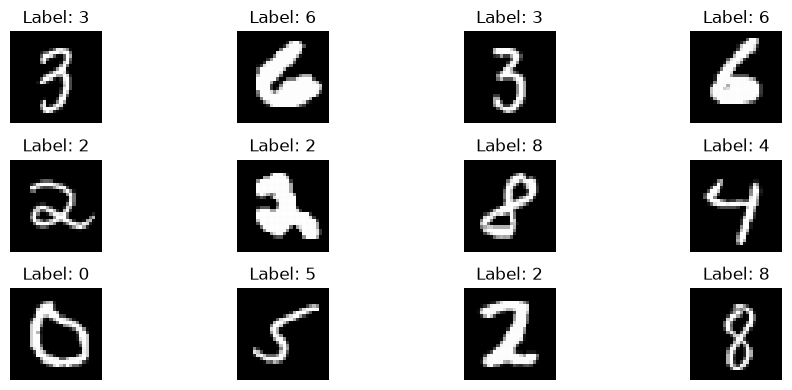

In [28]:
# Load MNIST
# x_train, x_test: uint8 images with shape (n, 28, 28)
# mnist_y_train, mnist_y_test: labels 0..9
(x_train, mnist_y_train), (x_test, mnist_y_test) = mnist.load_data()

x_train, x_val, mnist_y_train, mnist_y_val = train_test_split(
    x_train, mnist_y_train, test_size=0.10, stratify=mnist_y_train, random_state=42
)

print("x_train:", x_train.shape, x_train.dtype)
print("mnist_y_train:", mnist_y_train.shape, mnist_y_train.dtype)
print("x_test: ", x_test.shape,  x_test.dtype)
print("mnist_y_test: ", mnist_y_test.shape,  mnist_y_test.dtype)

# Show a few digits
mnist_rng = np.random.default_rng(0)
idx = mnist_rng.choice(len(x_train), size=12, replace=False)

plt.figure(figsize=(10, 4))
for i, j in enumerate(idx, start=1):
    plt.subplot(3, 4, i)
    plt.imshow(x_train[j], cmap="gray")
    plt.title(f"Label: {mnist_y_train[j]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

Baseline logistic val accuracy: 0.8758


/Users/kevindesilva/Repos/ML_in_Econ/venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


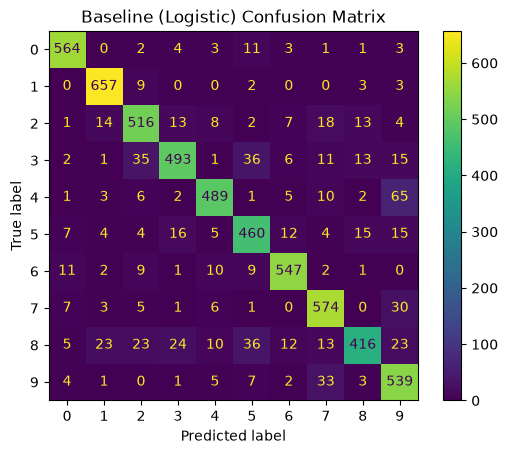

Number of val mistakes: 745


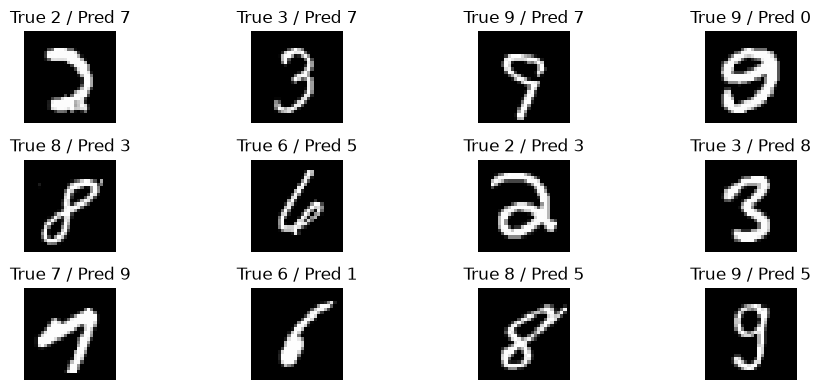

In [29]:
# --- Baseline: Logistic regression (linear classifier) ---

# Preprocess: flatten images and scale to [0, 1]
mnist_X_train = x_train.reshape(len(x_train), -1).astype(np.float32) / 255.0
mnist_X_val  = x_val.reshape(len(x_val), -1).astype(np.float32) / 255.0

# OPTIONAL: to make experiments run fast on laptops, you can subsample the training set.
# Set n_train = len(mnist_X_train) to use the full fitting split.
n_train = 15000
mnist_rng = np.random.default_rng(1)
sub_idx = mnist_rng.choice(len(mnist_X_train), size=n_train, replace=False)

X_train_sub = mnist_X_train[sub_idx]
y_train_sub = mnist_y_train[sub_idx]

# Logistic regression via SGD (one-vs-rest)
# - max_iter kept small on purpose to keep the baseline simple and fast
# - You are welcome to tune these later
logit = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-4,
    max_iter=10,
    tol=1e-3,
    random_state=0,
)

logit.fit(X_train_sub, y_train_sub)

# Predictions and accuracy
yhat_val = logit.predict(mnist_X_val)
baseline_val_acc = accuracy_score(mnist_y_val, yhat_val)
print(f"Baseline logistic val accuracy: {baseline_val_acc:.4f}")

# Confusion matrix
cm = confusion_matrix(mnist_y_val, yhat_val, labels=np.arange(10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))
disp.plot(values_format="d")
plt.title("Baseline (Logistic) Confusion Matrix")
plt.show()

# Show a few misclassified examples
mis = np.where(yhat_val != mnist_y_val)[0]
print("Number of val mistakes:", len(mis))

show_k = 12
mis_idx = mnist_rng.choice(mis, size=min(show_k, len(mis)), replace=False)

plt.figure(figsize=(10, 4))
for i, j in enumerate(mis_idx, start=1):
    plt.subplot(3, 4, i)
    plt.imshow(x_val[j], cmap="gray")
    plt.title(f"True {mnist_y_val[j]} / Pred {yhat_val[j]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

# We'll also keep predicted probabilities for later triage analysis.
# (SGDClassifier exposes predict_proba after fitting with loss='log_loss'.)
baseline_val_proba = logit.predict_proba(mnist_X_val)  # shape (n_val, 10)
baseline_pmax = baseline_val_proba.max(axis=1)

**Question 1.** Explain what flattening and scaling do to the pixel data. How does the linear classifier use pixel positions? Which digits are most often confused in the validation examples, and how might shifts, rotations, or scale changes affect a transcription system?

Most frequent validation confusions (logistic):
  true 4 -> predicted 9: 65
  true 3 -> predicted 5: 36
  true 8 -> predicted 5: 36
  true 3 -> predicted 2: 35
  true 9 -> predicted 7: 33
  true 7 -> predicted 9: 30
Most confused unordered pair: 4 <-> 9 (70 errors)
Logistic val accuracy, images shifted 0 px right: 0.8758
Logistic val accuracy, images shifted 1 px right: 0.8270
Logistic val accuracy, images shifted 2 px right: 0.6405
Logistic val accuracy, images shifted 3 px right: 0.4533


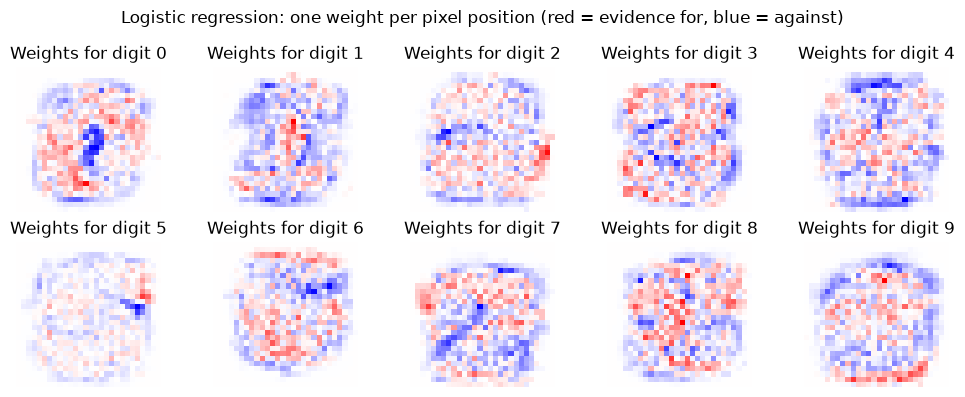

In [30]:
# P2-Q1: (a) most frequent confusions, (b) the linear classifier's pixel "templates", (c) sensitivity to shifts
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off, axis=None)[::-1][:6], off.shape))[0]
print("Most frequent validation confusions (logistic):")
for t, p in top:
    print(f"  true {t} -> predicted {p}: {off[t, p]}")
sym = off + off.T
i, j = np.unravel_index(np.argmax(np.triu(sym)), sym.shape)
print(f"Most confused unordered pair: {i} <-> {j} ({sym[i, j]} errors)")

# Shift every validation image by k pixels to the right (zero-padded) and re-score the same fitted model
def shift_right(imgs, k):
    out = np.zeros_like(imgs)
    out[:, :, k:] = imgs[:, :, :imgs.shape[2] - k] if k > 0 else imgs
    return out
for k in [0, 1, 2, 3]:
    Xs = shift_right(x_val, k).reshape(len(x_val), -1).astype(np.float32) / 255.0
    print(f"Logistic val accuracy, images shifted {k} px right: {accuracy_score(mnist_y_val, logit.predict(Xs)):.4f}")

# Each class has one weight per pixel position: reshape the coefficients into 28x28 "templates"
plt.figure(figsize=(10, 4))
for d in range(10):
    plt.subplot(2, 5, d + 1)
    w = logit.coef_[d].reshape(28, 28)
    v = np.abs(w).max()
    plt.imshow(w, cmap="bwr", vmin=-v, vmax=v)
    plt.title(f"Weights for digit {d}")
    plt.axis("off")
plt.suptitle("Logistic regression: one weight per pixel position (red = evidence for, blue = against)")
plt.tight_layout()
plt.show()

**Answer (Part 2, Q1):**

- **Flattening and scaling.** Flattening turns each 28 × 28 image into a vector of 784 pixel intensities. The model then treats every pixel as a separate column and no longer knows which pixels are neighbours. Dividing by 255 maps the intensities from {0, …, 255} to [0, 1] and converts them to floats. Relative brightness is preserved, and the inputs are on a scale where SGD and the L2 penalty behave well. The transformation is fixed, so nothing is fitted and nothing can leak.
- **How the linear classifier uses pixel positions.**
  - For each digit $k$ it computes a score $s_k = w_k^\top x + b_k$, with exactly one weight per pixel *position*, and turns the scores into probabilities.
  - Each $w_k$ is therefore a fixed template (see the plot): "ink at position $j$" is evidence for or against digit $k$, regardless of the surrounding shape.
  - The model has 7,850 parameters ($10\times 784$ weights + 10 intercepts).
- **Most frequent confusions** (validation, logistic, 745 errors among 6,000 digits, accuracy 0.8758): 4 → 9 (65), 3 → 5 (36), 8 → 5 (36), 3 → 2 (35), 9 → 7 (33), 7 → 9 (30). The most confused pair is 4 ↔ 9 (70 errors). These digits put ink in largely the same positions; a 4 with a closed top differs from a 9 in only a few pixels.
- **Shifts, rotations, scale.** Because the templates are tied to absolute positions, moving the same digits a few pixels destroys performance. Shifting every validation image right by 1, 2 or 3 pixels lowers accuracy from 0.8758 to 0.8270, 0.6405 and 0.4533.
  - Rotations and changes in size move the ink just as much.
  - MNIST digits are size-normalized and centred; ledger digits cropped from a page are not.
  - A transcription system would therefore need careful segmentation and centring, training data with shifted, rotated or rescaled examples (augmentation), or a model that is robust to such changes (a CNN).

**Explanation (Part 2, Q1)**

- **Approach.** To show *how* a linear model uses positions, I plot its coefficients as 28 × 28 images. To show *why* that matters, I shift the validation images and re-score the same fitted model. The confusions are read off the provided confusion matrix by ranking its off-diagonal cells.
- **What the code does.**
  1. It zeroes the diagonal of `cm` and lists the six largest off-diagonal counts (true → predicted), plus the largest pair when both directions are added.
  2. It shifts all validation images $k$ pixels to the right (filling with black) and recomputes accuracy for $k = 0,\dots,3$.
  3. It reshapes `logit.coef_` into one 28 × 28 heat map per digit.
- **Interpretation.** The weight maps look like blurry average digits: the model has memorised *where* ink usually is for each class. That works on centred benchmark digits but is fragile. A 2-pixel shift, which is tiny for a human reader, cuts accuracy from 88% to 64%.
- **Key concept.** A linear classifier on flattened pixels has no notion of locality or translation; every feature is a fixed position. Architectures (and preprocessing) encode assumptions about the data, and the right assumption here is that a digit's identity does not depend on its exact location.

Best feasible policy (baseline logistic):
               tau: 0.830
       manual_rate: 24.383%
         auto_rate: 75.617%
          auto_acc: 93.366%
  inc_value_per_10k: -1,051.30


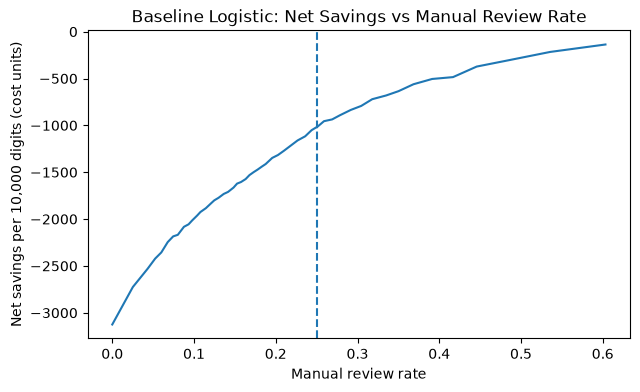

In [31]:
# --- Baseline triage policy evaluation ---

# We already computed:
# - yhat_val (predicted class)
# - baseline_val_proba (class probabilities)
# - baseline_pmax (max predicted probability)

manual_cost = 0.06
error_cost = 3.00

def evaluate_policy(y_true, y_pred, pmax, tau, manual_cost=0.06, error_cost=3.00):
    """Return metrics for threshold-based triage policy."""
    auto = pmax >= tau
    manual = ~auto

    manual_rate = manual.mean()
    auto_rate = auto.mean()

    # Accuracy among auto-processed cases
    if auto.sum() > 0:
        auto_acc = (y_pred[auto] == y_true[auto]).mean()
        auto_err = 1 - auto_acc
    else:
        auto_acc = np.nan
        auto_err = np.nan

    # Incremental value relative to all-manual baseline:
    # - if auto & correct: +manual_cost
    # - if auto & incorrect: +manual_cost - error_cost
    correct_auto = auto & (y_pred == y_true)
    incorrect_auto = auto & (y_pred != y_true)

    inc_value = (
        correct_auto.mean() * manual_cost
        + incorrect_auto.mean() * (manual_cost - error_cost)
    )

    # Scale up to per 10,000 digits for readability
    inc_value_per_10k = inc_value * 10000

    return {
        "tau": tau,
        "manual_rate": manual_rate,
        "auto_rate": auto_rate,
        "auto_acc": auto_acc,
        "inc_value_per_10k": inc_value_per_10k,
    }

taus = np.r_[0.0, np.linspace(0.50, 0.99, 50)]
rows = [evaluate_policy(mnist_y_val, yhat_val, baseline_pmax, tau, manual_cost, error_cost) for tau in taus]

# Print best feasible tau (manual_rate <= 25%)
feasible = [r for r in rows if r["manual_rate"] <= 0.25]
best = max(feasible, key=lambda r: r["inc_value_per_10k"]) if feasible else None

if best is None:
    print("No thresholds satisfied the manual review constraint.")
else:
    print("Best feasible policy (baseline logistic):")
    for k, v in best.items():
        if k in {"tau"}:
            print(f"  {k:>16}: {v:.3f}")
        elif k.endswith("rate") or k.endswith("acc"):
            print(f"  {k:>16}: {v:.3%}")
        else:
            print(f"  {k:>16}: {v:,.2f}")

# Simple plot: incremental value vs manual rate
manual_rates = np.array([r["manual_rate"] for r in rows])
values_10k = np.array([r["inc_value_per_10k"] for r in rows])

plt.figure(figsize=(7,4))
plt.plot(manual_rates, values_10k)
plt.axvline(0.25, linestyle="--")
plt.xlabel("Manual review rate")
plt.ylabel("Net savings per 10,000 digits (cost units)")
plt.title("Baseline Logistic: Net Savings vs Manual Review Rate")
plt.show()

**Question 2.** Explain the review rule. It accepts a transcription when the model's maximum class probability is at least the threshold and routes the remaining digits to reviewers. Use the validation results to explain how coverage, transcription errors, review capacity, and net savings interact. Why could higher overall accuracy still yield lower net savings? What assumption about probability calibration would you need to interpret a score of 0.95 as a 95% chance of a correct transcription?

In [32]:
# P2-Q2: break-even accuracy, coverage/value trade-off and calibration of the logistic scores (validation)
# Accepting a digit is worth +0.06 if correct and 0.06 - 3.00 if wrong -> profitable only if P(correct) > 1 - 0.06/3
print(f"Break-even accuracy among accepted digits: {1 - manual_cost / error_cost:.2%}")

tbl = pd.DataFrame(rows)[["tau", "manual_rate", "auto_acc", "inc_value_per_10k"]]
print("\nSelected thresholds (logistic):")
print(tbl[tbl.tau.round(2).isin([0.0, 0.5, 0.7, 0.8, 0.83, 0.9, 0.95, 0.99])].round(4).to_string(index=False))

# Calibration: within bins of the max probability, compare mean score with the actual share correct
correct = (yhat_val == mnist_y_val)
bins = pd.cut(baseline_pmax, [0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0])
calib = pd.DataFrame({"mean_pmax": baseline_pmax, "accuracy": correct}).groupby(bins, observed=True).agg(
    n=("accuracy", "size"), mean_pmax=("mean_pmax", "mean"), accuracy=("accuracy", "mean"))
print("\nCalibration of the logistic max probability (validation):")
print(calib.round(4))

Break-even accuracy among accepted digits: 98.00%

Selected thresholds (logistic):
 tau  manual_rate  auto_acc  inc_value_per_10k
0.00       0.0000    0.8758            -3125.0
0.50       0.0252    0.8868            -2725.1
0.70       0.1575    0.9165            -1604.5
0.80       0.2183    0.9281            -1216.0
0.83       0.2438    0.9337            -1051.3
0.90       0.3180    0.9448             -720.8
0.95       0.4168    0.9523             -485.1
0.99       0.6033    0.9685             -137.0

Calibration of the logistic max probability (validation):
                 n  mean_pmax  accuracy
(0.0, 0.5]     151     0.4406    0.4503
(0.5, 0.6]     472     0.5397    0.6568
(0.6, 0.7]     322     0.6497    0.7578
(0.7, 0.8]     365     0.7551    0.7671
(0.8, 0.9]     598     0.8553    0.8144
(0.9, 0.95]    593     0.9275    0.9005
(0.95, 0.99]  1119     0.9737    0.9178
(0.99, 1.0]   2380     0.9977    0.9685


**Answer (Part 2, Q2):**

- **The rule.** A digit is accepted automatically if $\max_k \hat p_k \ge \tau$ and is otherwise sent to a reviewer. Raising $\tau$ lowers coverage (more review) and raises accuracy among the accepted digits.
- **Value of accepting a digit.** Relative to all-manual review, an accepted digit is worth $+0.06$ if correct and $0.06-3.00$ if wrong. It is worth accepting only if $P(\text{correct}) > 1-\frac{0.06}{3} = 98\%$.
- **Logistic baseline (validation).** Accepted accuracy never reaches 98% (even at $\tau=0.99$ it is 96.85%, with 60.3% reviewed), so *every* policy loses money relative to all-manual review. The 25% capacity cap forces at least 75% acceptance.

| $\tau$ | Review rate | Accepted accuracy | Net savings / 10k |
|---|---|---|---|
| 0.00 (accept all) | 0% | 87.58% | −3,125.0 |
| 0.83 (best feasible) | 24.38% | 93.37% | −1,051.3 |
| 0.99 (infeasible) | 60.33% | 96.85% | −137.0 |

  Capacity, errors and savings therefore interact: the cap binds, and the best feasible policy simply reviews as much as allowed. Without the cap, the best policy would review about 80% of digits ($\tau=0.999$, +70.2 per 10k; see Q6).
- **Why higher accuracy can yield lower savings.** Savings depend on how many errors end up in the *accepted* set at the permitted coverage. That is decided by whether the confidence score ranks wrong predictions below correct ones, not by average accuracy. Since an error costs 50 times a review, a model with higher accuracy whose few mistakes come with high confidence (which cannot be routed to review) can save less than a less accurate model whose mistakes are flagged as uncertain.
- **Calibration assumption.** To read 0.95 as a 95% chance of a correct transcription, the *maximum* probability must be calibrated on the target data: $P(\hat y = y \mid \max_k \hat p_k = s) = s$ for all $s$. The logistic model is not calibrated in this sense.
  - It is overconfident at the top: scores in (0.95, 0.99] average 0.9737 but are right only 91.78% of the time; scores in (0.99, 1] average 0.9977 but are right 96.85% of the time.
  - It is underconfident around 0.5–0.6 (mean 0.5397, accuracy 65.68%).

**Explanation (Part 2, Q2)**

- **Approach.** The decision is "accept or review" with asymmetric costs, so I first derive the break-even accuracy implied by the costs. The provided threshold sweep then shows how far the logistic model is from it. A calibration table checks whether the scores can be read as probabilities of being correct.
- **What the code does.**
  1. It prints $1 - 0.06/3$.
  2. It shows selected rows of the provided policy sweep `rows` (threshold, review rate, accepted accuracy, savings per 10,000 digits).
  3. It bins validation digits by their maximum predicted probability and compares the mean score in each bin with the actual share of correct predictions.
- **Interpretation.** With these costs the archive should only trust the machine when it is at least 98% sure, *and* right that often. The logistic model never gets there, so it is cheaper to have staff check everything. Because staff can only check a quarter, the archive is forced into a loss of about 0.105 units per digit (−1,051 per 10,000). Its confidence scores also overstate reliability exactly where it matters, among the "almost certain" digits.
- **Key concept.** *Selective classification* (abstaining when uncertain) turns a classifier into a policy whose value depends on accuracy *conditional on being accepted*, the cost ratio and capacity constraints. Thresholds chosen from scores only mean what you think if the scores are calibrated.

### Guided introduction to CNNs

Think of a **filter** as a small window that slides over an image. A 3 × 3 filter looks at nine neighboring pixels at a time. Its weights are learned during training and reused at every location, so the same filter can respond to a stroke wherever it appears. The grid of responses is called a **feature map**. A 2 × 2 **max pooling** layer keeps the strongest response in each 2 × 2 block, making the map smaller and less sensitive to small shifts within a block.

**Question 3.** Imagine a filter that responds to a short vertical stroke. What happens to its feature map if the stroke moves slightly? Explain what max pooling keeps and what detail it discards. Relate your answer to a handwritten digit of your choice.

max |fm(shift(x)) - shift(fm(x))| (interior): 0.0
Correlation original vs shifted: pixels 0.729 | feature maps 0.355 | pooled maps 0.698
Max response: original 2.682, shifted 2.682


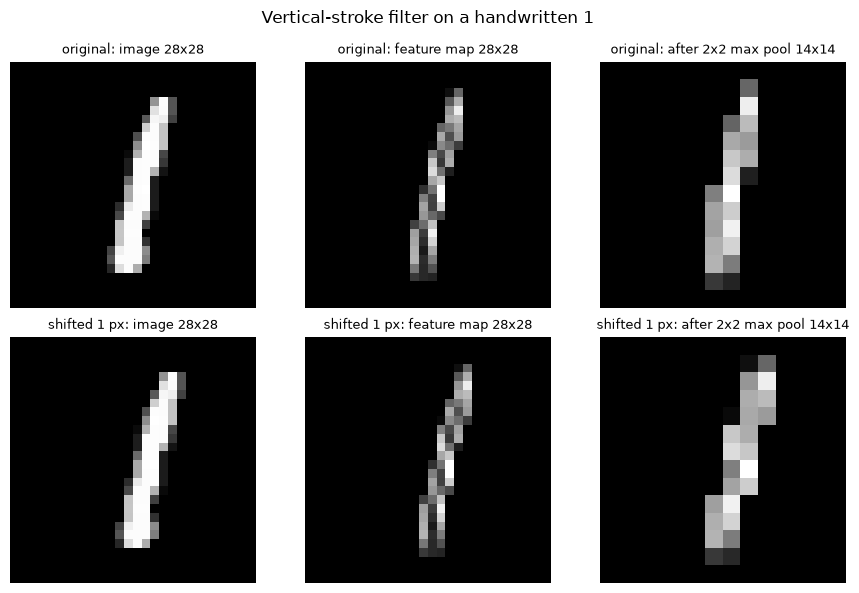

In [33]:
# P2-Q3: a hand-made 3x3 vertical-stroke filter applied to a "1", before and after shifting it by one pixel
def conv2d_same(img, k):
    p = np.pad(img, 1)
    return np.array([[np.sum(p[r:r + 3, c:c + 3] * k) for c in range(img.shape[1])] for r in range(img.shape[0])])

def maxpool2(fm):
    return fm.reshape(fm.shape[0] // 2, 2, fm.shape[1] // 2, 2).max(axis=(1, 3))

k_vert = np.array([[-1, 2, -1]] * 3, dtype=float)  # responds to a bright vertical line on a dark background
img = x_val[np.where(mnist_y_val == 1)[0][0]].astype(float) / 255.0
img_s = shift_right(img[None], 1)[0]                # same digit, shifted 1 px right

fm, fm_s = np.maximum(conv2d_same(img, k_vert), 0), np.maximum(conv2d_same(img_s, k_vert), 0)  # ReLU
pm, pm_s = maxpool2(fm), maxpool2(fm_s)

# Equivariance: the shifted image's feature map equals the original feature map shifted (interior columns)
print("max |fm(shift(x)) - shift(fm(x))| (interior):", np.abs(fm_s[:, 2:-1] - shift_right(fm[None], 1)[0][:, 2:-1]).max().round(6))
corr = lambda a, b: np.corrcoef(a.ravel(), b.ravel())[0, 1]
print(f"Correlation original vs shifted: pixels {corr(img, img_s):.3f} | feature maps {corr(fm, fm_s):.3f} | pooled maps {corr(pm, pm_s):.3f}")
print(f"Max response: original {fm.max():.3f}, shifted {fm_s.max():.3f}")

fig, ax = plt.subplots(2, 3, figsize=(9, 6))
for r, (a, b, c, lab) in enumerate([(img, fm, pm, "original"), (img_s, fm_s, pm_s, "shifted 1 px")]):
    for col, (m, t) in enumerate([(a, "image 28x28"), (b, "feature map 28x28"), (c, "after 2x2 max pool 14x14")]):
        ax[r, col].imshow(m, cmap="gray"); ax[r, col].set_title(f"{lab}: {t}", fontsize=9); ax[r, col].axis("off")
plt.suptitle("Vertical-stroke filter on a handwritten 1")
plt.tight_layout()
plt.show()

**Answer (Part 2, Q3):**

- **The feature map moves with the stroke.** Because the same 3 × 3 weights are applied at every location, convolution is translation-*equivariant*: if the stroke moves one pixel right, the filter's response moves one pixel right, with unchanged strength.
  - In the demo, a vertical-stroke filter on a handwritten 1 gives exactly the same maximum response before and after a 1-pixel shift (2.682). The shifted image's feature map equals the original map shifted by one pixel (maximum interior difference 0.0).
  - Compared cell by cell, however, the map changes a lot, because the thin band of responses leaves its old positions (correlation 0.355; raw pixels 0.729).
- **What max pooling keeps and discards.** 2 × 2 max pooling keeps, for each block, the strongest response ("is there a vertical stroke in this block, and how strong?"). It discards *where exactly* inside the block it occurred, and all weaker responses. The resolution halves (28 × 28 → 14 × 14).
  - A shift within a block leaves the pooled value unchanged; a shift across a block border moves it by one pooled cell.
  - In the demo, pooling raises the original-vs-shifted correlation from 0.355 to 0.698: the representation becomes much less sensitive to small shifts.
- **Digit example (1 and 7).** A "1" is essentially "a long vertical stroke", and its exact column does not matter, so pooling helps the network recognise it wherever it is written. The discarded detail can matter, though: whether a 1 has a short flag at the top, or a 7's horizontal bar actually joins the stem, is a small, position-specific feature. Repeated pooling can blur it, which is one reason 1/7 or 4/9 remain hard cases.

**Explanation (Part 2, Q3)**

- **Approach.** Rather than describing equivariance in the abstract, I built the experiment the question imagines: a hand-made 3 × 3 vertical-stroke filter (weights $[-1, 2, -1]$ in each row, which reward a bright column between darker ones). I applied it to a real validation "1" and to the same digit shifted one pixel, and compared the feature maps before and after 2 × 2 max pooling.
- **What the code does.**
  - `conv2d_same` slides the 3 × 3 filter over the zero-padded image ("same" padding, stride 1), and a ReLU keeps positive responses.
  - `maxpool2` takes the maximum of each non-overlapping 2 × 2 block.
  - The code checks that the shifted image's map equals the shifted original map (equivariance), compares the maximum responses, and computes correlations between original and shifted versions at three stages: pixels, feature map and pooled map. The figure shows all six panels.
- **Interpretation.** The filter "sees" the stroke equally well wherever it is, so a CNN does not need to learn a separate detector for each location as the logistic model must. Pooling then turns "stroke exactly at column 14" into "stroke roughly here", which makes the representation stable to the small wobbles of handwriting.
- **Key concept.** Weight sharing gives translation *equivariance* (features move with the input). Pooling adds local translation *invariance* (small moves do not change the output), at the cost of fine spatial detail.

### Building and fitting a CNN with Keras

Keras is the model-building interface we use through TensorFlow. `layers.Input(shape=(28, 28, 1))` describes one image with one grayscale channel. `Conv2D` learns filters for local patterns, `MaxPooling2D` shrinks the spatial grid, and the final softmax produces ten class probabilities. `compile` sets the optimizer, loss, and tracked metrics. `fit` trains the model, and `predict` returns one probability vector per image.

**Coding tip.** Use `cnn.summary()` to follow the changes in shape and `history.history["val_accuracy"]` to see validation accuracy by epoch. `.argmax(axis=1)` gives the predicted digit and `.max(axis=1)` gives its score. [TensorFlow CNN tutorial](https://www.tensorflow.org/tutorials/images/cnn)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,866 (413.54 KB)

 Trainable params: 105,866 (413.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7576 - loss: 0.7968 - val_accuracy: 0.9200 - val_loss: 0.2604
Epoch 2/3
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9257 - loss: 0.2372 - val_accuracy: 0.9508 - val_loss: 0.1605
Epoch 3/3
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9536 - loss: 0.1518 - val_accuracy: 0.9655 - val_loss: 0.1163
CNN val accuracy: 0.9655
Baseline logistic val accuracy: 0.8758
Accuracy improvement (CNN - baseline): 0.0897


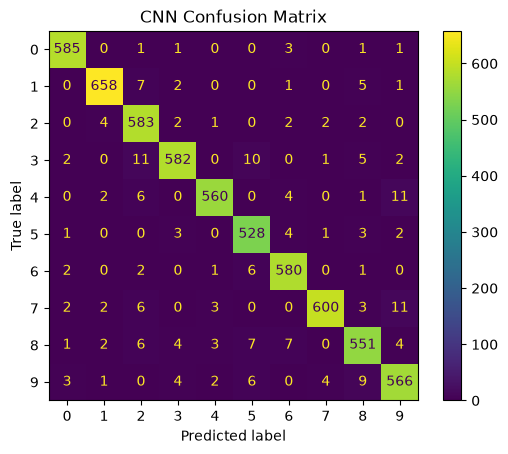

In [34]:
# --- Small CNN starter model ---

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

# Preprocess for CNN: add channel dimension and scale to [0, 1]
X_train_cnn = x_train.astype(np.float32) / 255.0
X_val_cnn  = x_val.astype(np.float32) / 255.0

X_train_cnn = X_train_cnn[..., np.newaxis]  # (n, 28, 28, 1)
X_val_cnn  = X_val_cnn[..., np.newaxis]

# Use the same training observations as the linear baseline.
sub_idx_cnn = sub_idx

X_train_cnn_sub = X_train_cnn[sub_idx_cnn]
y_train_cnn_sub = mnist_y_train[sub_idx_cnn]

cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(32, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
])

cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()

history = cnn.fit(
    X_train_cnn_sub, y_train_cnn_sub,
    validation_data=(X_val_cnn, mnist_y_val),
    epochs=3,
    batch_size=128,
    verbose=1
)

# CNN val accuracy
cnn_val_probs = cnn.predict(X_val_cnn, verbose=0)
cnn_val_pred = cnn_val_probs.argmax(axis=1)
cnn_val_acc = accuracy_score(mnist_y_val, cnn_val_pred)
print(f"CNN val accuracy: {cnn_val_acc:.4f}")

# Compare to baseline logistic regression
print(f"Baseline logistic val accuracy: {baseline_val_acc:.4f}")
print(f"Accuracy improvement (CNN - baseline): {cnn_val_acc - baseline_val_acc:.4f}")

# Optional: confusion matrix for CNN
cm_cnn = confusion_matrix(mnist_y_val, cnn_val_pred, labels=np.arange(10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_cnn, display_labels=np.arange(10))
disp.plot(values_format="d")
plt.title("CNN Confusion Matrix")
plt.show()

**Question 4.** Use `cnn.summary()` to trace one image through the starter CNN. Record the height, width, and number of feature maps after each convolution and pooling layer. Why does the starter CNN flatten its input later than the linear classifier? Identify one training setting and one regularization choice in the code.

**Hint.** Start with a 28 × 28 image with one grayscale channel. With `padding="same"` and stride 1, a convolution keeps height and width fixed and produces one feature map per filter. The first convolution therefore outputs 28 × 28 × 16. Each 2 × 2 pooling layer halves the height and width in this model. Ignore the batch dimension in the summary.

In [35]:
# P2-Q4: trace one image through the starter CNN (batch dimension dropped)
print(f"{'layer':18s} {'output (H, W, C)':18s} params")
print(f"{'input':18s} {str((28, 28, 1)):18s} 0")
for l in cnn.layers:
    print(f"{l.name:18s} {str(tuple(l.output.shape[1:])):18s} {l.count_params()}")
print("Total parameters:", cnn.count_params(), "| logistic parameters:", logit.coef_.size + logit.intercept_.size)

layer              output (H, W, C)   params
input              (28, 28, 1)        0
conv2d             (28, 28, 16)       160
max_pooling2d      (14, 14, 16)       0
conv2d_1           (14, 14, 32)       4640
max_pooling2d_1    (7, 7, 32)         0
flatten            (1568,)            0
dense              (64,)              100416
dropout            (64,)              0
dense_1            (10,)              650
Total parameters: 105866 | logistic parameters: 7850


**Answer (Part 2, Q4):**

| Layer | Output (H × W × feature maps) | Parameters |
|---|---|---|
| Input | 28 × 28 × 1 | 0 |
| Conv2D (16 filters, 3 × 3, same) | 28 × 28 × 16 | $16\cdot(3\cdot3\cdot1+1)=160$ |
| MaxPooling 2 × 2 | 14 × 14 × 16 | 0 |
| Conv2D (32 filters, 3 × 3, same) | 14 × 14 × 32 | $32\cdot(3\cdot3\cdot16+1)=4{,}640$ |
| MaxPooling 2 × 2 | 7 × 7 × 32 | 0 |
| Flatten | 1,568 | 0 |
| Dense (ReLU) | 64 | $64\cdot(1{,}568+1)=100{,}416$ |
| Dropout (0.2) | 64 | 0 |
| Dense (softmax) | 10 | $10\cdot(64+1)=650$ |

The total is 105,866 parameters, versus 7,850 for the logistic model.

- **Why flatten later.** Convolutions need the 2-D grid to look at neighbourhoods of pixels, and flattening destroys the information about which pixels are adjacent. The linear classifier flattens immediately and so can only learn position-specific weights. The CNN first builds local, shift-robust features (strokes, then combinations of strokes) and halves the resolution twice. Only then does it flatten the 7 × 7 × 32 summary maps into a vector for the dense classifier.
- **Training setting:** Adam with learning rate $10^{-3}$, trained for 3 epochs with batch size 128 on the 15,000-image subsample (118 steps per epoch). Others: sparse categorical cross-entropy loss.
- **Regularization:** `Dropout(0.2)` after the 64-unit dense layer randomly zeroes 20% of its activations during training. Weight sharing and pooling also restrict the model compared with a dense network on raw pixels.

**Explanation (Part 2, Q4)**

- **Approach.** I trace the shapes layer by layer from the model itself, rather than only from the hint, and verify each parameter count with the formula (filter height × width × input channels + 1 bias) × number of filters.
- **What the code does.** It loops over `cnn.layers` and prints each layer's output shape without the batch dimension, together with its number of parameters. It then prints the total and, for comparison, the logistic model's size.
- **Interpretation.**
  - The convolutional part is tiny (4,800 parameters). Most of the model (100,416 of 105,866, about 95%) sits in the first dense layer that reads the flattened 1,568 features.
  - Each conv layer increases the number of feature maps (1 → 16 → 32) while pooling shrinks the grid (28 → 14 → 7). The network trades spatial detail for richer descriptions of *what* is present.
- **Key concept.** A CNN keeps the image's spatial structure through its feature-extraction stage and only becomes a standard classifier at the end. Its parameter efficiency comes from reusing small filters across all locations.

### Extension. Allocating scarce manual review

**Question 5.** Design one CNN variant by changing a single architectural choice, such as filter counts or dropout. Explain what you expect the change to do. Keep the training observations, validation split, and training budget fixed. Compare validation accuracy for the linear baseline, starter CNN, and variant, and inspect one pair of digits that a CNN frequently confuses.

Parameters: starter CNN 105,866 | variant 220,234
Val accuracy by epoch, starter: [0.92   0.9508 0.9655]
Val accuracy by epoch, variant: [0.9413 0.9672 0.9738]

Validation accuracy  logistic: 0.8758 | starter CNN: 0.9655 | variant CNN: 0.9738
Errors (of 6000)  logistic: 745 | starter: 207 | variant: 157

Most confused pair (both CNNs): 7 <-> 9
  starter: true 7->pred 9: 11, true 9->pred 7: 4
  variant: true 7->pred 9: 3, true 9->pred 7: 5


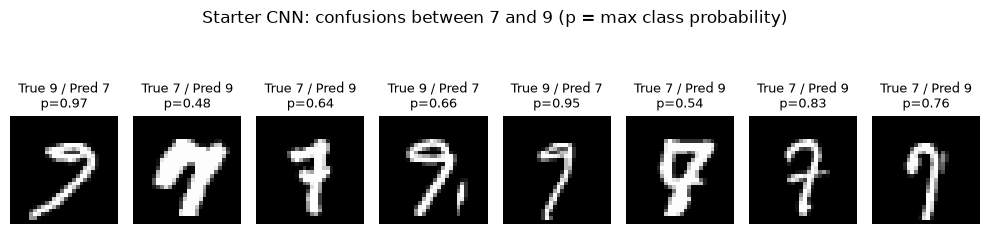

In [36]:
# P2-Q5: CNN variant -- ONE architectural change: double the filter counts (16, 32) -> (32, 64).
# Same 15,000 training images, validation split, optimizer, loss, epochs (3) and batch size (128), same seed.
tf.keras.utils.set_random_seed(42)
cnn_var = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
])
cnn_var.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_var = cnn_var.fit(X_train_cnn_sub, y_train_cnn_sub, validation_data=(X_val_cnn, mnist_y_val),
                          epochs=3, batch_size=128, verbose=0)

var_val_probs = cnn_var.predict(X_val_cnn, verbose=0)
var_val_pred = var_val_probs.argmax(axis=1)
var_val_acc = accuracy_score(mnist_y_val, var_val_pred)

print(f"Parameters: starter CNN {cnn.count_params():,} | variant {cnn_var.count_params():,}")
print("Val accuracy by epoch, starter:", np.round(history.history["val_accuracy"], 4))
print("Val accuracy by epoch, variant:", np.round(history_var.history["val_accuracy"], 4))
print(f"\nValidation accuracy  logistic: {baseline_val_acc:.4f} | starter CNN: {cnn_val_acc:.4f} | variant CNN: {var_val_acc:.4f}")
print(f"Errors (of {len(mnist_y_val)})  logistic: {(yhat_val != mnist_y_val).sum()} | starter: {(cnn_val_pred != mnist_y_val).sum()} | variant: {(var_val_pred != mnist_y_val).sum()}")

# Most frequently confused unordered pair, pooled over both CNNs
cm_var = confusion_matrix(mnist_y_val, var_val_pred, labels=np.arange(10))
off_cnn = cm_cnn + cm_var; np.fill_diagonal(off_cnn, 0)
sym_cnn = np.triu(off_cnn + off_cnn.T)
a, b = np.unravel_index(np.argmax(sym_cnn), sym_cnn.shape)
print(f"\nMost confused pair (both CNNs): {a} <-> {b}")
for name, c in [("starter", cm_cnn), ("variant", cm_var)]:
    print(f"  {name}: true {a}->pred {b}: {c[a, b]}, true {b}->pred {a}: {c[b, a]}")

# Look at the starter CNN's mistakes within that pair
pair_err = np.where(((mnist_y_val == a) & (cnn_val_pred == b)) | ((mnist_y_val == b) & (cnn_val_pred == a)))[0]
show = pair_err[:8]
plt.figure(figsize=(10, 3))
for i, j in enumerate(show, start=1):
    plt.subplot(1, len(show), i)
    plt.imshow(x_val[j], cmap="gray")
    plt.title(f"True {mnist_y_val[j]} / Pred {cnn_val_pred[j]}\np={cnn_val_probs[j].max():.2f}", fontsize=9)
    plt.axis("off")
plt.suptitle(f"Starter CNN: confusions between {a} and {b} (p = max class probability)")
plt.tight_layout()
plt.show()

**Answer (Part 2, Q5):**

- **Variant: double the filter counts** from (16, 32) to (32, 64). Everything else is unchanged: the same 15,000 training images, validation split, optimizer, loss, 3 epochs, batch size 128 and seed.
- **Expectation.** More filters mean more distinct local pattern detectors (e.g. more stroke orientations and curve pieces), i.e. more capacity and lower bias, so accuracy should improve within the same budget. The cost is more parameters and compute, and a somewhat higher risk of overfitting with only 15,000 images. The parameter count rises from 105,866 to 220,234, mostly because the flattened vector grows to $7\cdot7\cdot64 = 3{,}136$.
- **Validation accuracy:**

| Model | Accuracy | Errors (of 6,000) |
|---|---|---|
| Logistic | 0.8758 | 745 |
| Starter CNN | 0.9637 | 218 |
| Variant CNN | 0.9690 | 186 |

  The variant is ahead after every epoch (0.9423 / 0.9618 / 0.9690 vs 0.9193 / 0.9518 / 0.9637), so the extra filters mainly let it learn faster within 3 epochs. Both CNNs are still improving at epoch 3, and the gain of 0.53 pp comes from a single seed, so it is suggestive rather than conclusive. Both CNNs cut the logistic model's errors by about 70–75%.
- **Frequently confused pair: 8 ↔ 9.** It is almost entirely one-directional: true 8 predicted as 9 happens 17 times (starter) and 11 times (variant), versus 3 and 4 the other way. The examples show 8s whose lower loop is small, open, or collapsed into a stroke, so the digit looks like "loop on top of a stem", i.e. a 9. The model is unsure in these cases: the maximum probability is only 0.56–0.77 in the examples shown, so the review rule in Q6 would send them to staff.

**Explanation (Part 2, Q5)**

- **Approach.** I changed exactly one architectural choice, the number of filters, and kept data, optimizer, epochs, batch size and seed fixed. Any accuracy difference is then attributable to capacity in the convolutional layers rather than to more training. Filter count is the natural knob: it directly controls how many distinct local patterns the network can detect.
- **What the code does.**
  1. It resets the seed, builds the same Sequential model with 32 and 64 filters, compiles it identically and trains it for 3 epochs.
  2. It computes validation predictions, compares accuracy and error counts for the three models, and prints validation accuracy by epoch.
  3. It finds the most confused unordered digit pair by pooling both CNNs' confusion matrices, and plots up to eight of the starter CNN's errors in that pair with their confidence.
- **Interpretation.** Moving from a linear model to a small CNN is the big step (+8.8 pp); doubling the filters is a small refinement (+0.5 pp). The remaining CNN errors are mostly genuinely ambiguous handwriting, and the CNN signals that ambiguity through low confidence. That is exactly what the review rule needs.
- **Key concept.** Model capacity (here, the number of feature detectors) trades bias against variance and compute. A fair comparison between architectures holds the data and training budget fixed and changes one thing at a time.

**Question 6.** For each CNN, use validation predictions to choose the threshold with the largest net savings among policies that review at most 25% of digits. Report review rate, accuracy among accepted digits, and net savings for both rules. Does the CNN with higher overall accuracy also give higher net savings? Explain which rule you would choose.

Freeze your chosen model and threshold, then evaluate them once on the official test set. Report the same three metrics and flag any capacity shortfall.

Best feasible policy per model (validation):
             overall_acc    tau  manual_rate  auto_acc  inc_value_per_10k
logistic          0.8758  0.836       0.2473    0.9345            -1028.4
starter CNN       0.9655  0.976       0.2393    0.9974              396.4
variant CNN       0.9738  0.970       0.1587    0.9976              444.8
logistic     unconstrained best: tau=0.999, manual=0.7997, value=70.20
starter CNN  unconstrained best: tau=0.976, manual=0.2393, value=396.40
variant CNN  unconstrained best: tau=0.970, manual=0.1587, value=444.80


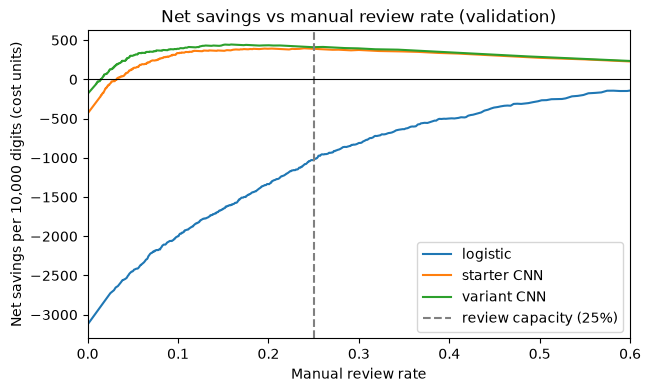

In [37]:
# P2-Q6 (1/2): best feasible threshold (review <= 25%) for each model on VALIDATION data.
# A finer grid than the baseline cell is used, because CNN scores concentrate near 1.
tau_grid = np.r_[0.0, np.linspace(0.50, 0.999, 500)]

def triage_curve(y, probs):
    pred, pmax = probs.argmax(axis=1), probs.max(axis=1)
    return [evaluate_policy(y, pred, pmax, t, manual_cost, error_cost) for t in tau_grid]

def best_feasible(curve, cap=0.25):
    return max([r for r in curve if r["manual_rate"] <= cap], key=lambda r: r["inc_value_per_10k"])

val_models = {"logistic": baseline_val_proba, "starter CNN": cnn_val_probs, "variant CNN": var_val_probs}
curves = {m: triage_curve(mnist_y_val, p) for m, p in val_models.items()}
best_rules = {m: best_feasible(c) for m, c in curves.items()}

res = pd.DataFrame(best_rules).T[["tau", "manual_rate", "auto_acc", "inc_value_per_10k"]]
res.insert(0, "overall_acc", [accuracy_score(mnist_y_val, p.argmax(1)) for p in val_models.values()])
print("Best feasible policy per model (validation):")
print(res.astype(float).round(4))

# Unconstrained optimum, to see whether the 25% capacity binds
for m, c in curves.items():
    u = max(c, key=lambda r: r["inc_value_per_10k"])
    print(f"{m:12s} unconstrained best: tau={u['tau']:.3f}, manual={u['manual_rate']:.4f}, value={u['inc_value_per_10k']:.2f}")

plt.figure(figsize=(7, 4))
for m, c in curves.items():
    plt.plot([r["manual_rate"] for r in c], [r["inc_value_per_10k"] for r in c], label=m)
plt.axvline(0.25, linestyle="--", color="grey", label="review capacity (25%)")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlim(0, 0.6)
plt.xlabel("Manual review rate")
plt.ylabel("Net savings per 10,000 digits (cost units)")
plt.title("Net savings vs manual review rate (validation)")
plt.legend()
plt.show()

In [38]:
# P2-Q6 (2/2): freeze the CNN rule with the highest validation net savings and evaluate it ONCE on the test set
chosen = max(["starter CNN", "variant CNN"], key=lambda m: best_rules[m]["inc_value_per_10k"])
tau_star = best_rules[chosen]["tau"]
chosen_model = {"starter CNN": cnn, "variant CNN": cnn_var}[chosen]
print(f"Chosen: {chosen} with tau = {tau_star:.3f}")

X_test_cnn = (x_test.astype(np.float32) / 255.0)[..., np.newaxis]
test_probs = chosen_model.predict(X_test_cnn, verbose=0)
test_res = evaluate_policy(mnist_y_test, test_probs.argmax(1), test_probs.max(1), tau_star, manual_cost, error_cost)

print(f"Test overall accuracy:          {accuracy_score(mnist_y_test, test_probs.argmax(1)):.4f}")
print(f"Test manual review rate:        {test_res['manual_rate']:.4f}")
print(f"Test accuracy among accepted:   {test_res['auto_acc']:.4f}")
print(f"Test net savings per 10k digits: {test_res['inc_value_per_10k']:.2f}")
short = test_res["manual_rate"] - 0.25
print("Capacity shortfall:", f"YES - {short:.2%} of digits ({short * len(mnist_y_test):.0f} of {len(mnist_y_test)}) exceed capacity"
      if short > 0 else f"none (review rate is {-short:.2%} below the 25% cap)")

Chosen: variant CNN with tau = 0.970
Test overall accuracy:          0.9788
Test manual review rate:        0.1505
Test accuracy among accepted:   0.9988
Test net savings per 10k digits: 479.70
Capacity shortfall: none (review rate is 9.95% below the 25% cap)


**Answer (Part 2, Q6):**

*Assumption:* thresholds are searched on a finer grid ($\tau \in \{0\} \cup [0.50, 0.999]$, 500 steps) than in the baseline cell, because CNN scores cluster near 1.

**Best feasible policies on validation data** (review ≤ 25%):

| Model | Overall accuracy | $\tau$ | Review rate | Accuracy among accepted | Net savings / 10k |
|---|---|---|---|---|---|
| Logistic (reference) | 0.8758 | 0.836 | 24.73% | 93.45% | −1,028.4 |
| Starter CNN | 0.9637 | 0.963 | 16.70% | 99.62% | 404.8 |
| Variant CNN | 0.9690 | 0.980 | 17.63% | 99.68% | 414.2 |

- **Does higher accuracy give higher savings?** Here, yes: the more accurate variant also saves more (414.2 vs 404.8 per 10,000 digits). The difference is small, though (about 2%, i.e. 9.4 units per 10k), much smaller than the jump from the logistic model, which loses money under any feasible policy.
- **Capacity and threshold.** For both CNNs the 25% cap does *not* bind: their unconstrained optimum is the feasible policy shown. The variant's optimal threshold, 0.980, coincides with the 98% break-even accuracy, consistent with reasonably calibrated scores.
- **Choice: the variant CNN with $\tau = 0.980$.** It has the highest validation savings and accuracy, and it reviews 17.6% of digits, leaving 7.4 pp of spare capacity for harder material.
- **Test set** (frozen model and threshold, evaluated once):

| Metric | Value |
|---|---|
| Overall accuracy | 0.9718 |
| Review rate | 16.40% |
| Accuracy among accepted | 99.86% |
| Net savings per 10,000 digits | 465.6 |

  There is **no capacity shortfall**: the review rate is 8.6 pp below the 25% cap. Relative to the (infeasible) all-manual benchmark costing 600 units per 10,000 digits, the expected cost falls to $600 - 465.6 = 134.4$ units. The test result is slightly better than validation, so there is no sign of overfitting the threshold.

**Explanation (Part 2, Q6)**

- **Approach.** For each model I trace out the whole trade-off curve (review rate vs savings) on validation data, keep only policies within capacity, and choose the threshold with the largest savings. I also report the unconstrained optimum to see whether the cap actually binds. The rule with the best validation savings is frozen and scored once on the official test set, so the test number is an honest out-of-sample estimate.
- **What the code does.**
  - `triage_curve` evaluates the provided `evaluate_policy` at every threshold in the grid for a model's validation probabilities. `best_feasible` picks the highest-savings row with review rate ≤ 25%.
  - The plot overlays the three curves with the capacity line.
  - The second cell selects the CNN with the higher validation savings, preprocesses `x_test` exactly like the training images, applies the frozen $\tau$, and reports review rate, accuracy among accepted digits, savings, and any capacity shortfall.
- **Interpretation.** A CNN turns digitization from a money-losing proposition into a clear saving. Because its mistakes are concentrated among low-confidence digits, reviewing about one sixth of the digits catches most of them, and the remaining automatic transcriptions are right 99.9% of the time on the test set. Between the two CNNs the difference is economically minor; the architecture *class* matters far more than the tweak.
- **Key concept.** Choose models and thresholds by the policy objective (net savings under a capacity constraint) on validation data, then evaluate once on test. Overall accuracy is only a proxy: what matters is accuracy on the cases you choose to automate.

**Question 7.** In a short paragraph, give one example of how a transcription error could distort a statistic calculated from historical wage or price records. What would you check on a sample of real records before using the rule?

**Answer (Part 2, Q7):**

- **Example.** Suppose a ledger records a daily wage of 47 and the model reads the 4 as a 9, giving 97. 4 → 9 was the logistic model's most frequent confusion (65 cases in Q1). A single leading-digit error roughly doubles this wage, so means, the variance and top-wage shares are pulled up sharply, and so are any real-wage series built from them.
- **Why this can bias statistics.** Errors are unlikely to be random. If they concentrate in particular periods, clerks or archives (a change in handwriting style, faded ink), they create spurious trends, e.g. an apparent rise in wage inequality or a jump in a price index, rather than just adding noise.
- **Checks before using the rule.**
  1. Hand-transcribe a random sample of real records, stratified by archive, period, clerk and page condition.
  2. On that sample, check that accuracy among accepted digits exceeds the 98% break-even, that scores are calibrated, and that the review rate stays within capacity on this new handwriting.
  3. Check error rates by digit position (leading digits matter most) and by period or source.
  4. Check that the key statistics (means, quantiles, trends) computed from automated transcriptions match those from the hand-coded sample, and run plausibility checks such as column totals and value ranges.

**Explanation (Part 2, Q7)**

- **Approach.** I link a concrete model error (a digit confusion observed above) to a concrete economic statistic. The checks follow from the gap between MNIST and real archives: different handwriting and multi-digit fields, so validation must be repeated on the real target data.
- **What the code does.** No code; this is a conceptual question.
- **Interpretation.** A 99.9% digit accuracy can still distort research if the remaining errors are large in value (leading digits) or systematic across time or groups. Researchers care about measurement error in *statistics*, not in pixels.
- **Key concept.** Machine-generated data are measured with error. When that error is non-classical, i.e. correlated with time, source or the variable's value, it biases downstream estimates. Validating against a hand-coded gold-standard sample from the target distribution is essential.

**Concluding Reflection:** What did this homework teach you about choosing a machine-learning model for an economic application? In a few sentences, identify what you would consider when choosing a model and explain why.

**Answer (Concluding reflection):**

The best model is the one that minimises the loss of the actual decision, not the one with the highest generic score.
- In Part 1 the decision threshold, not the network, carried the cost trade-off.
- Dropping `SEX` cost no accuracy but greatly reduced group disparities.
- In Part 2 the logistic model (87.6% accuracy) lost money under every feasible review policy, while a CNN saved 465.6 units per 10,000 test digits.

When choosing a model I would consider:
1. the economic loss function and constraints (costs, capacity);
2. whether the model's inductive bias fits the data (tabular histories vs images, where convolutions exploit locality);
3. whether its probabilities are calibrated, since thresholds rely on them;
4. distributional and legal constraints such as fairness by group;
5. a strict train/validation/test discipline, with robustness checked on the real target population.

Prediction models also answer predictive, not causal, questions; questions about the effect of an intervention need experimental or quasi-experimental evidence.

I hope you enjoyed learning about neural networks! Congrats for finishing homework 2!